# **Project Name**    - Zomato Restaurant Clustering & Sentiment Analysis (Hyderabad)

##### **Project Type**    - Unsupervised ML (Clustering) + NLP Sentiment Analysis
##### **Contribution**    - Individual
##### **Team Member 1 -** NA
##### **Team Member 2 -** NA
##### **Team Member 3 -** NA
##### **Team Member 4 -** NA

# **Project Summary -**

Zomato is one of India's largest restaurant aggregators. In this project I worked with two files from Zomato for **Gachibowli, Hyderabad**: a **restaurant metadata** file (105 restaurants with name, link, cost for two, Zomato collections, cuisines and timings) and a **reviews** file (10,000 reviews with reviewer, review text, rating, reviewer metadata, time and number of pictures). The goals given in the project brief were: (1) analyse customer sentiment from the reviews, (2) **cluster the restaurants into segments**, and (3) turn the results into insights that help customers find the best restaurant and help Zomato see where it is lagging.

**Data understanding and cleaning.** The metadata had cost stored as text ("1,300"), 51% missing `Collections` (meaning *not in any collection*) and one missing `Timings`. The reviews had 36 fully blank duplicate rows, 38 rows with no rating, 7 reviews with a rating but no text, and one non-numeric rating ("Like"). After cleaning, **9,954 reviews** were kept. I parsed reviewer metadata into *number of reviews* and *followers*, split timestamps into year/month/hour/weekday, calculated review length, and created a sentiment label from the star rating (≥4 Positive, 3–3.5 Neutral, ≤2.5 Negative). Reviews were then aggregated per restaurant and merged with the metadata (5 restaurants without reviews were median-imputed and flagged).

**EDA (15 charts, UBM rule).** The typical cost for two is **Rs 700 (median)**, and the distribution is right-skewed up to Rs 2,800. **North Indian (61 restaurants) and Chinese (43)** dominate the cuisines. Ratings are polarised: **63% positive vs 24.6% negative**, with very few half-star ratings. Cost and rating are **moderately positively related (Spearman ρ = 0.38)**: premium restaurants average 3.94 against 3.38 for budget ones. Review activity peaks on **weekends and between 9 PM and 11 PM**. Reviews with pictures rate higher (3.86 vs 3.53), and high-follower "critics" write about 3.6× longer reviews and give fewer negative ratings.

**Hypothesis testing.** Three tests confirmed the visual findings at α = 0.05: cost vs rating (Spearman, p = 0.0001), pictures vs rating (Mann-Whitney U, p = 0.002) and price band vs sentiment (Chi-square, p ≈ 7e-54).

**Feature engineering and preprocessing.** Outliers were capped with the IQR method so that no restaurant was dropped. The 44 multi-label cuisines were one-hot encoded and then summarised into **5 cuisine-family shares** (Indian, Asian, Continental/Western, Quick-bites, Cafe & Desserts). Highly correlated features were removed (pct_positive ~ avg_rating r = 0.98, avg_pictures ~ review length r = 0.81). Skewed columns were log-transformed, everything was standardised, and PCA reduced 11 features to 7 components (90% variance). For text, I built a full NLP pipeline: contraction expansion, lower-casing, punctuation/URL/digit removal, stop-word removal (negations such as *not* were kept), slang normalisation, tokenisation, lemmatisation and TF-IDF (unigrams + bigrams).

**Models.** (1) **K-Means**, tuned with the elbow method, a silhouette grid (k = 2–10, two init methods) and a 10-seed stability check, gave **4 segments** (silhouette 0.284, ARI stability 1.0). (2) **Agglomerative clustering** (dendrogram + grid over linkage × k) gave lower silhouette (best valid 0.249), so K-Means was selected. The segments are: *Premium Continental/Multi-cuisine, high-rated* (43 restaurants, avg Rs 1,294, rating 3.84), *Mid-priced Indian, low-rated* (38, Rs 611, 3.39), *Budget Cafe & Desserts* (16, Rs 497, 3.62) and *Budget Quick-bites, low-rated* (8, Rs 456, 3.32). (3) A **sentiment classifier** (TF-IDF + Logistic Regression, class-balanced, tuned with 5-fold GridSearchCV against Naive Bayes) reached **94.3% accuracy, F1 0.96 and ROC-AUC 0.984** on unseen reviews.

**Outcome.** Customers can be matched to the right segment, Zomato can focus on the low-rated segments, and negative reviews can be flagged automatically. Both models are saved with joblib and tested on unseen data.

# **GitHub Link -**

Provide your GitHub Link here. *(e.g. https://github.com/your-username/Zomato-Restaurant-Clustering)*

# **Problem Statement**


**Zomato has thousands of restaurants and lakhs of free-text reviews, but it has no simple, data-driven way to group similar restaurants or to know automatically whether a customer is happy or unhappy.**

Using the restaurant metadata (cost, cuisines, collections) and customer reviews for Hyderabad (Gachibowli), the objectives are:

1. **Analyse customer sentiment** in the reviews and identify what drives positive and negative experiences.
2. **Cluster the restaurants into meaningful segments** (unsupervised ML) based on cost, cuisine mix, popularity and customer ratings.
3. Do a **cost vs. benefit analysis** (is a higher price justified by a higher rating?) and find the most popular cuisines.
4. Use the **reviewer metadata** to identify critics / influential reviewers.
5. Turn the findings into recommendations that help **customers** find the best restaurant in their locality and help **Zomato** improve in the areas where it is lagging.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# ==============================================================
# Import Libraries
# ==============================================================
# Core data handling
import os
import re
import string
import warnings
from collections import Counter

import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage

# Machine learning (scikit-learn)
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
import joblib

# ---------------- Global settings ----------------
warnings.filterwarnings('ignore')            # keep the output clean
RANDOM_STATE = 42                            # reproducibility everywhere
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# One consistent, colour-blind-friendly palette used for every chart
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
BLUE, ORANGE, AQUA = PALETTE[0], PALETTE[1], PALETTE[2]
sns.set_theme(style='whitegrid', palette=PALETTE)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.titlesize': 13, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})

# NLTK is OPTIONAL (only used for POS-tagging demo). The rest of the notebook never depends on it,
# so the notebook runs in one go even where NLTK / internet is not available.
try:
    import nltk
    NLTK_AVAILABLE = True
except ImportError:
    NLTK_AVAILABLE = False

print('Libraries imported successfully | pandas', pd.__version__, '| NLTK available:', NLTK_AVAILABLE)

Libraries imported successfully | pandas 3.0.5 | NLTK available: False


### Dataset Loading

In [2]:
# Load Dataset
# File names as provided by Labmentix. In Google Colab, upload both CSVs in the Files panel
# (or mount Google Drive and change DATA_DIR accordingly).
DATA_DIR = '.'
META_PATH = os.path.join(DATA_DIR, 'Zomato_Restaurant_names_and_Metadata.csv')
REVIEW_PATH = os.path.join(DATA_DIR, 'Zomato_Restaurant_reviews.csv')


def load_csv(path: str) -> pd.DataFrame:
    """Read a CSV safely and give a helpful message if the file is missing."""
    try:
        df = pd.read_csv(path)
        print(f'Loaded {os.path.basename(path):45s} -> shape {df.shape}')
        return df
    except FileNotFoundError:
        raise FileNotFoundError(f'"{path}" not found. Upload the file or update DATA_DIR.')


meta_df = load_csv(META_PATH)      # restaurant level data (1 row = 1 restaurant)
review_df = load_csv(REVIEW_PATH)  # review level data     (1 row = 1 customer review)

Loaded Zomato_Restaurant_names_and_Metadata.csv      -> shape (105, 6)
Loaded Zomato_Restaurant_reviews.csv                 -> shape (10000, 7)


### Dataset First View

In [3]:
# Dataset First Look
print('Restaurant metadata:')
display(meta_df.head())
print('Customer reviews:')
display(review_df.head())

Restaurant metadata:


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


Customer reviews:


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
for name, df in [('Restaurant metadata', meta_df), ('Reviews', review_df)]:
    print(f'{name:20s}: {df.shape[0]:>6,} rows | {df.shape[1]} columns')

Restaurant metadata :    105 rows | 6 columns
Reviews             : 10,000 rows | 7 columns


In [5]:
# How well do the two files link? (Name in metadata  <->  Restaurant in reviews)
meta_names, review_names = set(meta_df['Name']), set(review_df['Restaurant'])
print('Restaurants in metadata          :', len(meta_names))
print('Restaurants having reviews       :', len(review_names))
print('Restaurants WITHOUT any review   :', sorted(meta_names - review_names))
print('Reviews for unknown restaurants  :', len(review_names - meta_names))
print('Reviews per restaurant (min/max) :', review_df['Restaurant'].value_counts().agg(['min', 'max']).tolist())

Restaurants in metadata          : 105
Restaurants having reviews       : 100
Restaurants WITHOUT any review   : ['Angaara Counts 3', 'IndiBlaze', 'Republic Of Noodles - Lemon Tree Hotel', 'Sweet Basket', 'Wich Please']
Reviews for unknown restaurants  : 0
Reviews per restaurant (min/max) : [100, 100]


### Dataset Information

In [6]:
# Dataset Info
print('=' * 25, 'Restaurant metadata', '=' * 25)
meta_df.info()
print('\n' + '=' * 30, 'Reviews', '=' * 30)
review_df.info()

========================= Restaurant metadata =========================
<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Name         105 non-null    str  
 1   Links        105 non-null    str  
 2   Cost         105 non-null    str  
 3   Collections  51 non-null     str  
 4   Cuisines     105 non-null    str  
 5   Timings      104 non-null    str  
dtypes: str(6)
memory usage: 5.1 KB

============================== Reviews ==============================
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Restaurant  10000 non-null  str  
 1   Reviewer    9962 non-null   str  
 2   Review      9955 non-null   str  
 3   Rating      9962 non-null   str  
 4   Metadata    9962 non-null   str  
 5   Time        9962 non-null   str  


#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
print('Duplicate rows in metadata :', meta_df.duplicated().sum())
print('Duplicate rows in reviews  :', review_df.duplicated().sum())
# Are the review duplicates real reviews or blank rows?
dups = review_df[review_df.duplicated()]
print('Of these duplicates, rows that are completely blank (no reviewer / review / rating):',
      int(dups[['Reviewer', 'Review', 'Rating']].isna().all(axis=1).sum()))

Duplicate rows in metadata : 0
Duplicate rows in reviews  : 36
Of these duplicates, rows that are completely blank (no reviewer / review / rating): 36


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
print('Restaurant metadata - missing values:')
display(meta_df.isna().sum().to_frame('missing').assign(pct=lambda d: (d['missing'] / len(meta_df) * 100).round(2)))
print('Reviews - missing values:')
display(review_df.isna().sum().to_frame('missing').assign(pct=lambda d: (d['missing'] / len(review_df) * 100).round(2)))

Restaurant metadata - missing values:


,missing,pct
Name,0,0.00
Links,0,0.00
Cost,0,0.00
Collections,54,51.43
Cuisines,0,0.00
Timings,1,0.95


Reviews - missing values:


,missing,pct
Restaurant,0,0.00
Reviewer,38,0.38
Review,45,0.45
Rating,38,0.38
Metadata,38,0.38
Time,38,0.38
Pictures,0,0.00


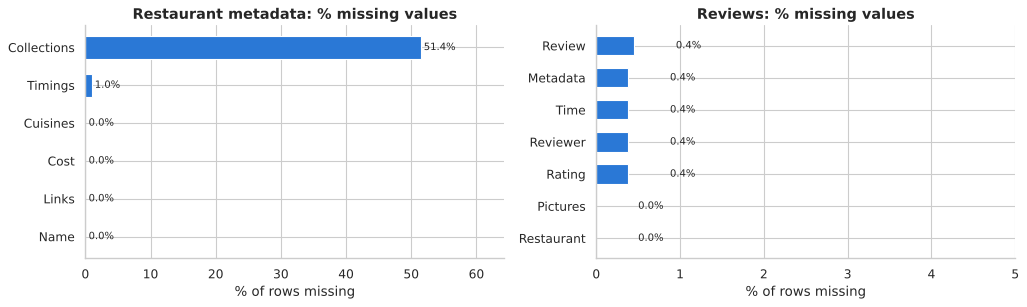

In [9]:
# Visualizing the missing values (% of rows missing per column)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, df) in zip(axes, [('Restaurant metadata', meta_df), ('Reviews', review_df)]):
    pct = df.isna().mean().mul(100).sort_values()
    ax.barh(pct.index, pct.values, color=BLUE, height=0.6)
    for y, v in enumerate(pct.values):
        ax.text(v + 0.5, y, f'{v:.1f}%', va='center', fontsize=9)
    ax.set_title(f'{name}: % missing values')
    ax.set_xlabel('% of rows missing')
    ax.set_xlim(0, max(pct.max() * 1.25, 5))
plt.tight_layout()
plt.show()

### What did you know about your dataset?

* There are **two datasets**: `Zomato_Restaurant_names_and_Metadata.csv` (**105 rows × 6 columns**, one row per restaurant) and `Zomato_Restaurant_reviews.csv` (**10,000 rows × 7 columns**, one row per review).
* They link through `Name` ↔ `Restaurant`. **100 restaurants have exactly 100 reviews each**; 5 restaurants (Angaara Counts 3, IndiBlaze, Republic Of Noodles, Sweet Basket, Wich Please) have no reviews at all.
* **Every column is read as text**: `Cost` contains commas ("1,300"), `Rating` contains a non-numeric value "Like", and `Time` and `Metadata` are strings that have to be parsed.
* **Duplicates:** none in the metadata. The reviews have 36 duplicate rows, and all 36 are completely blank rows (no reviewer, text or rating).
* **Missing values:** `Collections` is 51.4% missing (the restaurant is not in any Zomato collection), `Timings` has 1 missing value, and the reviews have about 0.4% missing in Reviewer/Rating/Metadata/Time (the same blank rows) plus 7 extra reviews with no text.
* `Cuisines` and `Collections` are **multi-valued** comma-separated fields, so they need special encoding.
* The data has **no target label for restaurants**, so restaurant segmentation is an **unsupervised clustering** problem. For reviews, the star rating can be used as a sentiment label.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
print('Metadata columns :', meta_df.columns.tolist())
print('Review columns   :', review_df.columns.tolist())

Metadata columns : ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Review columns   : ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [11]:
# Dataset Describe (all columns - numeric and text)
display(meta_df.describe(include='all').T)
display(review_df.describe(include='all').T)

,count,unique,top,freq
Name,105,105,Beyond Flavours,1
Links,105,105,https://www.zomato.com/hyderabad/beyond-flavou...,1
Cost,105,29,500,13
Collections,51,42,Food Hygiene Rated Restaurants in Hyderabad,4
Cuisines,105,92,"North Indian, Chinese",4
Timings,104,77,11 AM to 11 PM,6


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant,10000,100,Beyond Flavours,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviewer,9962,7446,Ankita,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review,9955,9364,good,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9962,10,5,3832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metadata,9962,2477,1 Review,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9962,9782,5/5/2019 22:39,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pictures,10000.0,NaN,NaN,NaN,0.7486,2.570381,0.0,0.0,0.0,0.0,64.0


### Variables Description

**Restaurant metadata**

| Variable | Description | Type |
|---|---|---|
| Name | Name of the restaurant (unique key) | Text |
| Links | Zomato URL of the restaurant | Text (identifier) |
| Cost | Estimated cost for two people (Rs) | Numeric (stored as text) |
| Collections | Zomato tags / curated lists the restaurant belongs to (e.g. *Great Buffets*) | Multi-label categorical |
| Cuisines | Cuisines served (e.g. *North Indian, Chinese*) | Multi-label categorical |
| Timings | Opening hours | Text |

**Reviews**

| Variable | Description | Type |
|---|---|---|
| Restaurant | Restaurant name (foreign key to `Name`) | Categorical |
| Reviewer | Name of the reviewer | Text |
| Review | Review text | Free text (NLP) |
| Rating | Star rating, 1–5 in steps of 0.5 | Numeric (stored as text) |
| Metadata | Reviewer's total reviews and followers, e.g. "12 Reviews , 7 Followers" | Text, parsed into 2 numbers |
| Time | Date and time of the review (May 2016 – May 2019) | Datetime |
| Pictures | Number of pictures posted with the review | Numeric (0–64) |

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
for name, df in [('Restaurant metadata', meta_df), ('Reviews', review_df)]:
    print(f'--- {name} ---')
    print(df.nunique().to_string(), '\n')
print('Raw values found in Rating column:', review_df['Rating'].unique().tolist())

--- Restaurant metadata ---
Name           105
Links          105
Cost            29
Collections     42
Cuisines        92
Timings         77 

--- Reviews ---
Restaurant     100
Reviewer      7446
Review        9364
Rating          10
Metadata      2477
Time          9782
Pictures        36 

Raw values found in Rating column: ['5', '4', '1', '3', '2', '3.5', '4.5', '2.5', '1.5', 'Like', nan]


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.

# ---------- 3.1 Restaurant metadata ----------
def clean_metadata(df: pd.DataFrame) -> pd.DataFrame:
    """Clean the restaurant metadata and create helper columns."""
    df = df.copy()
    # Cost is stored as text like "1,300" -> convert to integer rupees
    df['Cost'] = pd.to_numeric(df['Cost'].astype(str).str.replace(',', '', regex=False), errors='coerce')
    # Cuisines / Collections are comma separated -> python lists (strip extra spaces)
    df['Cuisine_list'] = df['Cuisines'].fillna('').apply(lambda s: [c.strip() for c in s.split(',') if c.strip()])
    df['Collection_list'] = df['Collections'].fillna('').apply(lambda s: [c.strip() for c in s.split(',') if c.strip()])
    df['n_cuisines'] = df['Cuisine_list'].str.len()
    df['n_collections'] = df['Collection_list'].str.len()
    # Price band (business friendly bucket of cost for two)
    df['Price_band'] = pd.cut(df['Cost'], bins=[0, 500, 1000, np.inf],
                              labels=['Budget (<=500)', 'Mid (501-1000)', 'Premium (>1000)'])
    return df


# ---------- 3.2 Reviews ----------
def parse_reviewer_metadata(text):
    """'12 Reviews , 7 Followers' -> (12, 7). Missing parts -> 0."""
    if pd.isna(text):
        return 0, 0
    reviews = re.search(r'(\d+)\s*Review', str(text))
    followers = re.search(r'(\d+)\s*Follower', str(text))
    return (int(reviews.group(1)) if reviews else 0, int(followers.group(1)) if followers else 0)


def clean_reviews(df: pd.DataFrame) -> pd.DataFrame:
    """Clean the review data and engineer reviewer / time / text helper columns."""
    df = df.copy()
    before = len(df)
    df = df.drop_duplicates()                                       # exact duplicate rows
    df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')      # 'Like' -> NaN
    df = df.dropna(subset=['Rating', 'Review'])                      # rating & text are our core signals
    print(f'Reviews kept: {len(df):,} of {before:,} (removed {before - len(df)})')

    # Reviewer metadata -> two numeric columns
    df[['reviewer_total_reviews', 'reviewer_followers']] = df['Metadata'].apply(
        lambda x: pd.Series(parse_reviewer_metadata(x)))
    # Review timestamp -> datetime parts
    df['Time'] = pd.to_datetime(df['Time'], format='%m/%d/%Y %H:%M', errors='coerce')
    df['Year'] = df['Time'].dt.year
    df['Month'] = df['Time'].dt.to_period('M').astype(str)
    df['Hour'] = df['Time'].dt.hour
    df['Weekday'] = df['Time'].dt.day_name()
    # Text helpers
    df['Review'] = df['Review'].astype(str)
    df['review_length'] = df['Review'].str.split().str.len()
    df['has_pictures'] = (df['Pictures'] > 0).astype(int)
    # Sentiment label derived from star rating
    df['Sentiment'] = pd.cut(df['Rating'], bins=[0, 2.5, 3.5, 5],
                             labels=['Negative', 'Neutral', 'Positive'])
    return df.reset_index(drop=True)


meta_clean = clean_metadata(meta_df)
reviews = clean_reviews(review_df)

# ---------- 3.3 Restaurant level aggregation of reviews + merge ----------
agg = reviews.groupby('Restaurant').agg(
    avg_rating=('Rating', 'mean'),
    n_reviews=('Rating', 'size'),
    pct_positive=('Sentiment', lambda s: (s == 'Positive').mean() * 100),
    avg_pictures=('Pictures', 'mean'),
    avg_review_len=('review_length', 'mean'),
    avg_reviewer_followers=('reviewer_followers', 'mean')).reset_index()

restaurants = meta_clean.merge(agg, how='left', left_on='Name', right_on='Restaurant').drop(columns='Restaurant')
print('Final restaurant-level table:', restaurants.shape)
display(restaurants[['Name', 'Cost', 'Price_band', 'n_cuisines', 'n_collections',
                     'avg_rating', 'n_reviews', 'pct_positive']].head())

Reviews kept: 9,954 of 10,000 (removed 46)
Final restaurant-level table: (105, 17)


,Name,Cost,Price_band,n_cuisines,n_collections,avg_rating,n_reviews,pct_positive
0,Beyond Flavours,800,Mid (501-1000),6,6,4.28,100.0,82.0
1,Paradise,800,Mid (501-1000),3,1,4.70,100.0,96.0
2,Flechazo,1300,Premium (>1000),4,2,4.66,100.0,91.0
3,Shah Ghouse Hotel & Restaurant,800,Mid (501-1000),5,1,3.21,100.0,53.0
4,Over The Moon Brew Company,1200,Premium (>1000),5,5,4.34,100.0,87.0


### What all manipulations have you done and insights you found?

**Manipulations done**
1. `Cost`: removed commas → integer rupees. Created **`Price_band`** (Budget ≤ 500, Mid 501–1000, Premium > 1000).
2. `Cuisines` / `Collections`: split into clean Python lists → **`n_cuisines`**, **`n_collections`**.
3. Reviews: dropped 36 blank duplicate rows, converted `Rating` to numeric ("Like" → NaN), dropped rows without a rating or text → **9,954 reviews kept**.
4. Parsed reviewer `Metadata` → **`reviewer_total_reviews`** and **`reviewer_followers`**.
5. Parsed `Time` → **Year, Month, Hour, Weekday**.
6. Created **`review_length`** (words), **`has_pictures`** and **`Sentiment`** (Positive ≥ 4, Neutral 3–3.5, Negative ≤ 2.5).
7. Aggregated reviews per restaurant (avg rating, number of reviews, % positive, avg pictures, avg review length, avg reviewer followers) and **left-joined** them to the metadata → one analysis-ready table of 105 restaurants.

**First insights**
* All reviewed restaurants have exactly 100 reviews, so review *count* cannot measure popularity here. Rating and sentiment are the useful signals.
* Example: *Paradise* (Rs 800) has an average rating of 4.70, while *Shah Ghouse Hotel* (same Rs 800) has only 3.21. The same price can come with very different customer satisfaction.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

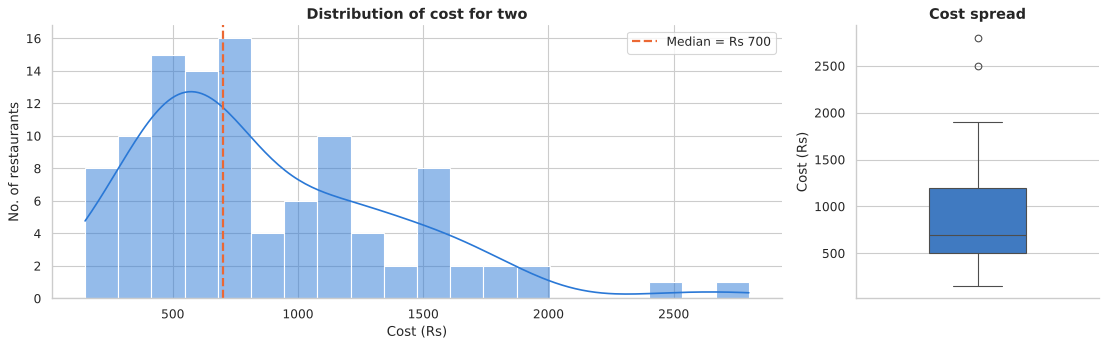

count     105.0
mean      861.0
std       510.0
min       150.0
25%       500.0
50%       700.0
75%      1200.0
max      2800.0
Skewness: 1.14


In [14]:
# Chart - 1 visualization code : Distribution of cost for two (Univariate)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [3, 1]})
sns.histplot(restaurants['Cost'], bins=20, kde=True, color=BLUE, ax=axes[0])
axes[0].axvline(restaurants['Cost'].median(), color=ORANGE, ls='--', lw=2,
                label=f"Median = Rs {restaurants['Cost'].median():.0f}")
axes[0].set(title='Distribution of cost for two', xlabel='Cost (Rs)', ylabel='No. of restaurants')
axes[0].legend()
sns.boxplot(y=restaurants['Cost'], color=BLUE, ax=axes[1], width=0.4)
axes[1].set(title='Cost spread', ylabel='Cost (Rs)')
plt.tight_layout()
plt.show()
print(restaurants['Cost'].describe().round(0).to_string())
print('Skewness:', round(restaurants['Cost'].skew(), 2))

##### 1. Why did you pick the specific chart?

A **histogram with KDE** shows the shape of a single continuous variable (where most restaurants are priced, skewness, gaps). The **box plot** next to it shows the median, IQR and outliers at a glance.

##### 2. What is/are the insight(s) found from the chart?

* Median cost for two is **Rs 700** (mean Rs 861), and 50% of restaurants are between Rs 500 and Rs 1,200.
* The distribution is **right-skewed (skew = 1.14)**: most places are affordable, with a long tail of premium hotel restaurants.
* Only two outliers are above Rs 2,250: *Collage – Hyatt* (Rs 2,800) and *Feast – Sheraton* (Rs 2,500).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Zomato can set its default price filters and 'pocket friendly' collections around the Rs 500–1,200 sweet spot where most supply sits. **Negative signal:** there are very few options above Rs 1,500, so premium diners have limited choice. That is a gap Zomato could fill by onboarding more fine-dining partners.

#### Chart - 2

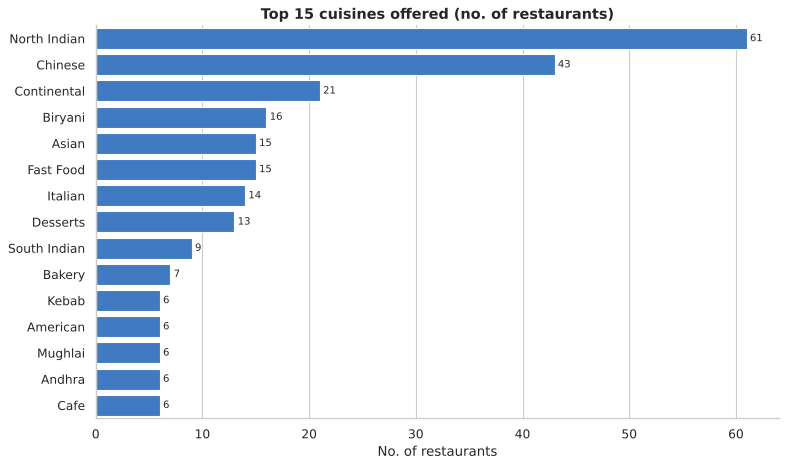

Total distinct cuisines: 44


In [15]:
# Chart - 2 visualization code : Most common cuisines (Univariate)
cuisine_counts = restaurants['Cuisine_list'].explode().value_counts()
top_cuisines = cuisine_counts.head(15)
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=top_cuisines.values, y=top_cuisines.index, color=BLUE)
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
ax.set(title='Top 15 cuisines offered (no. of restaurants)', xlabel='No. of restaurants', ylabel='')
plt.tight_layout()
plt.show()
print('Total distinct cuisines:', cuisine_counts.size)

##### 1. Why did you pick the specific chart?

A **horizontal bar chart** is the clearest way to compare counts across many categories with long names, sorted from most to least frequent.

##### 2. What is/are the insight(s) found from the chart?

* **North Indian (61 of 105 restaurants)** and **Chinese (43)** dominate. Continental (21) is a distant third.
* There are 44 distinct cuisines, but most of them (e.g. Goan, Spanish, Malaysian) appear in only 1–2 restaurants.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Zomato and new restaurant partners know that North Indian and Chinese have the most demand, but also the most competition. **Negative / risk:** the market is saturated with the same two cuisines, so new entrants offering them will struggle to stand out. Under-served cuisines (South Indian with only 9, Asian, Mediterranean) are an opportunity for differentiation.

#### Chart - 3

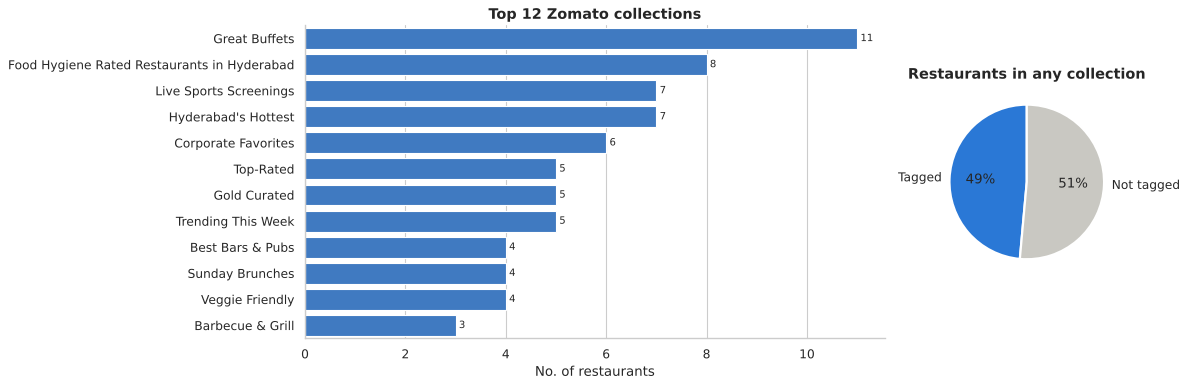

In [16]:
# Chart - 3 visualization code : Zomato collections / tags (Univariate)
collection_counts = restaurants['Collection_list'].explode().dropna().value_counts()
top_coll = collection_counts.head(12)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [3, 1]})
sns.barplot(x=top_coll.values, y=top_coll.index, color=BLUE, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], padding=3, fontsize=9)
axes[0].set(title='Top 12 Zomato collections', xlabel='No. of restaurants', ylabel='')
# How many restaurants are tagged at all?
tagged = (restaurants['n_collections'] > 0).map({True: 'Tagged', False: 'Not tagged'}).value_counts().reindex(['Tagged', 'Not tagged'])
axes[1].pie(tagged.values, labels=tagged.index, autopct='%1.0f%%', colors=[BLUE, '#c9c8c2'],
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Restaurants in any collection')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A **bar chart** ranks the Zomato collections, and a **pie chart** shows the simple two-part split of how many restaurants are tagged at all.

##### 2. What is/are the insight(s) found from the chart?

* **Great Buffets (11)**, *Food Hygiene Rated* (8), *Live Sports Screenings* (7) and *Hyderabad's Hottest* (7) are the most common tags.
* **51% of restaurants are not in any collection**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** collections act as free marketing, so Zomato can push restaurants that qualify (e.g. hygiene-rated) to get tagged and gain visibility. **Negative:** half of the restaurants get no curated exposure, which may reduce their discovery and orders. Zomato could create more inclusive collections (e.g. *Best Budget Biryani*) to cover them.

#### Chart - 4

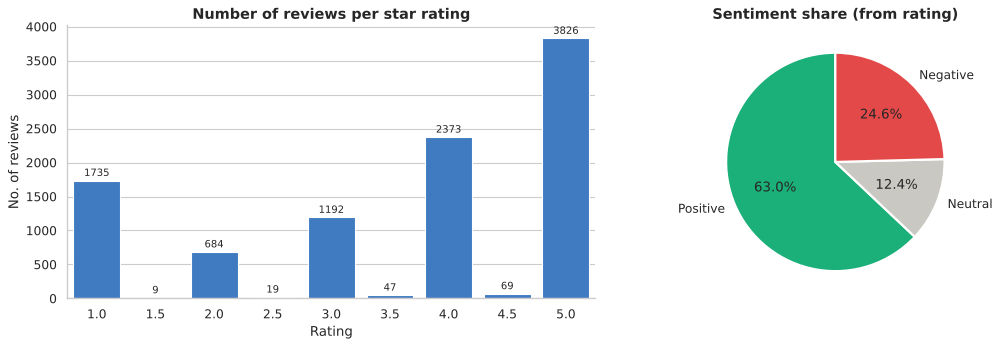

Mean rating: 3.6 | Median rating: 4.0


In [17]:
# Chart - 4 visualization code : Distribution of review ratings (Univariate)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rating_counts = reviews['Rating'].value_counts().sort_index()
sns.barplot(x=rating_counts.index.astype(str), y=rating_counts.values, color=BLUE, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], padding=2, fontsize=9)
axes[0].set(title='Number of reviews per star rating', xlabel='Rating', ylabel='No. of reviews')
sent_counts = reviews['Sentiment'].value_counts().reindex(['Positive', 'Neutral', 'Negative'])
axes[1].pie(sent_counts.values, labels=sent_counts.index, autopct='%1.1f%%',
            colors=[AQUA, '#c9c8c2', PALETTE[7]], startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Sentiment share (from rating)')
plt.tight_layout()
plt.show()
print('Mean rating:', round(reviews['Rating'].mean(), 2), '| Median rating:', reviews['Rating'].median())

##### 1. Why did you pick the specific chart?

A **count bar chart** shows how often each star value is given, and the **pie chart** shows the share of each sentiment class (a part-to-whole comparison with only 3 parts).

##### 2. What is/are the insight(s) found from the chart?

* Ratings are **polarised**: 5★ (3,826) is the most common value, but 1★ (1,735) is the third most common, more than 2★ and 3★.
* **63% of reviews are positive, 24.6% negative and 12.4% neutral**. Half-star ratings are rare.
* Mean rating 3.6, median 4.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** most customers are satisfied. **Negative growth signal:** about 1 in 4 reviews is negative, and unhappy customers mostly give the harshest score (1★). This means bad experiences are strongly felt and can quickly damage a restaurant's rating. These negative reviews should be monitored and answered quickly. The imbalance (63/25) also has to be handled when training the sentiment model.

#### Chart - 5

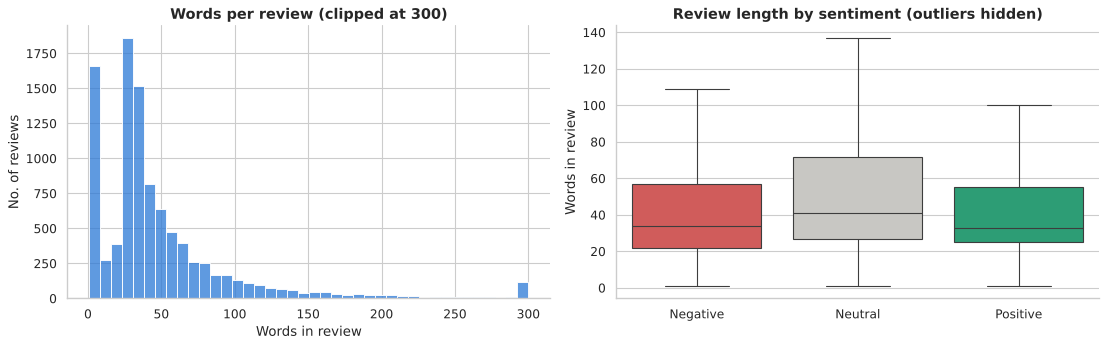

Sentiment
Negative    34.0
Neutral     41.0
Positive    33.0


In [18]:
# Chart - 5 visualization code : Review length (Univariate) and length by sentiment (Bivariate)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(reviews['review_length'].clip(upper=300), bins=40, color=BLUE, ax=axes[0])
axes[0].set(title='Words per review (clipped at 300)', xlabel='Words in review', ylabel='No. of reviews')
order = ['Negative', 'Neutral', 'Positive']
sns.boxplot(data=reviews, x='Sentiment', y='review_length', order=order, showfliers=False,
            palette=[PALETTE[7], '#c9c8c2', AQUA], ax=axes[1])
axes[1].set(title='Review length by sentiment (outliers hidden)', xlabel='', ylabel='Words in review')
plt.tight_layout()
plt.show()
print(reviews.groupby('Sentiment', observed=True)['review_length'].median().rename('median_words').to_string())

##### 1. Why did you pick the specific chart?

A **histogram** shows the distribution of review length (univariate), and a **box plot by sentiment** compares the length across the three sentiment groups.

##### 2. What is/are the insight(s) found from the chart?

* Most reviews are short. The median is 34 words, with a long tail of detailed reviews (clipped at 300).
* **Neutral reviews are the longest** (median 41 words): customers explain the mixed parts of their experience. Positive and negative reviews have similar median lengths (33–34 words).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** neutral (3★) reviews contain the most detailed and balanced feedback, which is the best source of improvement ideas for restaurants. No direct negative impact, but very short reviews such as *'good'* (the most repeated review, 237 times) carry little information for analysis.

#### Chart - 6

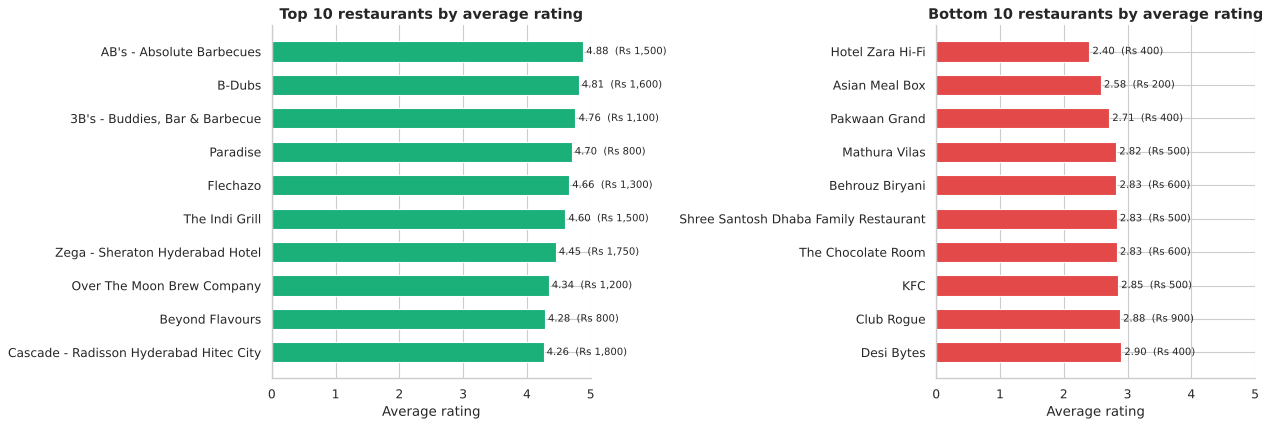

In [19]:
# Chart - 6 visualization code : Best and worst rated restaurants (Bivariate: categorical - numerical)
rated = restaurants.dropna(subset=['avg_rating']).sort_values('avg_rating')
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
top10 = rated.tail(10)
bottom10 = rated.head(10).iloc[::-1]
axes[0].barh(top10['Name'], top10['avg_rating'], color=AQUA, height=0.6)
axes[0].set(title='Top 10 restaurants by average rating', xlabel='Average rating', xlim=(0, 5))
axes[1].barh(bottom10['Name'], bottom10['avg_rating'], color=PALETTE[7], height=0.6)
axes[1].set(title='Bottom 10 restaurants by average rating', xlabel='Average rating', xlim=(0, 5))
for ax, d in [(axes[0], top10), (axes[1], bottom10)]:
    for y, (v, c) in enumerate(zip(d['avg_rating'], d['Cost'])):
        ax.text(v + 0.05, y, f'{v:.2f}  (Rs {c:,.0f})', va='center', fontsize=9)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

**Two side-by-side horizontal bar charts** compare the best and worst restaurants on the same 0–5 scale, with cost labels added to connect quality and price.

##### 2. What is/are the insight(s) found from the chart?

* **Top:** AB's – Absolute Barbecues (4.88), B-Dubs (4.81), 3B's (4.76), Paradise (4.70), Flechazo (4.66). Most of them are **premium (Rs 1,100–1,800)** buffets/grills, but *Paradise* stands out at only Rs 800.
* **Bottom:** Hotel Zara Hi-Fi (2.40), Asian Meal Box (2.58), Pakwaan Grand (2.71) are all **budget (Rs 200–600)**. Even big brands like **KFC (2.85)** and Behrouz Biryani (2.83) are in the bottom 10.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Zomato can promote the top-rated places in 'Top-Rated' collections, and customers get reliable recommendations. **Negative:** the bottom-10 restaurants risk losing customers and hurt Zomato's platform experience. Zomato's partner team should share review insights with them (e.g. food quality and delivery complaints) before customers leave the platform.

#### Chart - 7

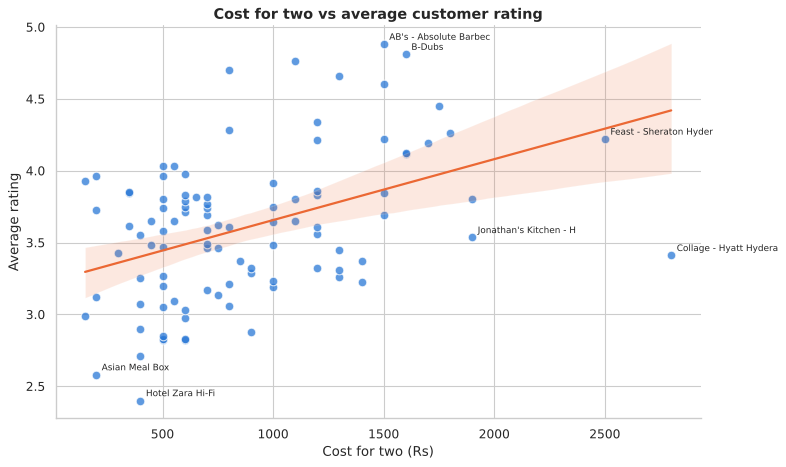

Pearson r = 0.422 | Spearman rho = 0.384


In [20]:
# Chart - 7 visualization code : Is cost correlated with rating? (Bivariate: numerical - numerical)
plt.figure(figsize=(10, 6))
sns.regplot(data=rated, x='Cost', y='avg_rating', color=BLUE,
            scatter_kws={'s': 60, 'alpha': 0.75, 'edgecolor': 'white'}, line_kws={'color': ORANGE, 'lw': 2})
# label only a few interesting points (most / least expensive and extreme ratings)
to_label = pd.concat([rated.nlargest(3, 'Cost'), rated.nsmallest(2, 'avg_rating'), rated.nlargest(2, 'avg_rating')])
for _, r in to_label.drop_duplicates('Name').iterrows():
    plt.annotate(r['Name'][:22], (r['Cost'], r['avg_rating']), xytext=(5, 4), textcoords='offset points', fontsize=8)
plt.title('Cost for two vs average customer rating')
plt.xlabel('Cost for two (Rs)')
plt.ylabel('Average rating')
plt.tight_layout()
plt.show()
print('Pearson r =', round(rated['Cost'].corr(rated['avg_rating']), 3),
      '| Spearman rho =', round(rated['Cost'].corr(rated['avg_rating'], method='spearman'), 3))

##### 1. Why did you pick the specific chart?

A **scatter plot with a regression line** is the standard way to see the relationship between two numeric variables (cost vs rating), including its direction, strength and outliers.

##### 2. What is/are the insight(s) found from the chart?

* **Moderate positive relationship: Pearson r = 0.42, Spearman ρ = 0.38.** Higher-priced restaurants tend to get better ratings.
* The spread is still large: some **budget places score above 3.9** (good value for money), while expensive hotel restaurants such as *Collage – Hyatt* (Rs 2,800, 3.41) and *Jonathan's Kitchen* (Rs 1,900, 3.54) underperform.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** price is a signal of quality, but not a guarantee. Zomato can build a **'value for money'** badge for restaurants that are rated above the trend line for their price. **Negative:** expensive restaurants with low ratings create the worst customer disappointment (high expectation, poor experience). These are the most important ones to fix.

#### Chart - 8

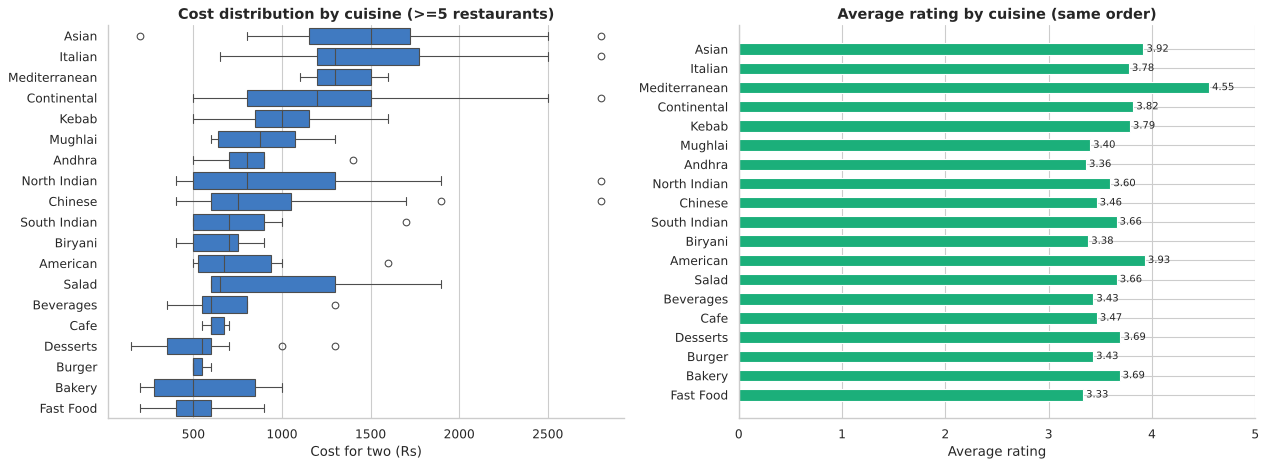

In [21]:
# Chart - 8 visualization code : Cost & rating across cuisines (Bivariate: categorical - numerical)
cuisine_long = restaurants[['Name', 'Cost', 'avg_rating', 'Cuisine_list']].explode('Cuisine_list')
common = cuisine_counts[cuisine_counts >= 5].index            # cuisines served by >= 5 restaurants
cuisine_long = cuisine_long[cuisine_long['Cuisine_list'].isin(common)]
order_cost = cuisine_long.groupby('Cuisine_list')['Cost'].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=cuisine_long, y='Cuisine_list', x='Cost', order=order_cost, color=BLUE, ax=axes[0])
axes[0].set(title='Cost distribution by cuisine (>=5 restaurants)', xlabel='Cost for two (Rs)', ylabel='')
cuisine_rating = cuisine_long.groupby('Cuisine_list')['avg_rating'].mean().reindex(order_cost)
axes[1].barh(cuisine_rating.index, cuisine_rating.values, color=AQUA, height=0.6)
axes[1].invert_yaxis()
axes[1].set(title='Average rating by cuisine (same order)', xlabel='Average rating', xlim=(0, 5))
for y, v in enumerate(cuisine_rating.values):
    axes[1].text(v + 0.03, y, f'{v:.2f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A **box plot per cuisine** shows the full cost distribution for each category (cost distribution across cuisines was one of the questions in the project architecture). The **bar chart next to it, in the same order**, adds average rating, so price and satisfaction can be read together.

##### 2. What is/are the insight(s) found from the chart?

* **Most expensive cuisines (median):** Asian (Rs 1,500), Italian & Mediterranean (Rs 1,300), Continental (Rs 1,200). **Cheapest:** Fast Food, Burger, Bakery (Rs 500).
* **Mediterranean has the highest average rating (4.55)**, followed by American (3.93) and Asian (3.92). **Fast Food (3.33), Andhra (3.36) and Biryani (3.38)** have the lowest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Mediterranean and Asian are high-price, high-satisfaction niches that are worth promoting and expanding. **Negative:** Biryani is one of Hyderabad's signature foods, yet it is among the lowest-rated cuisines. Unhappy biryani customers are a real threat to repeat orders, so quality in this category deserves attention.

#### Chart - 9

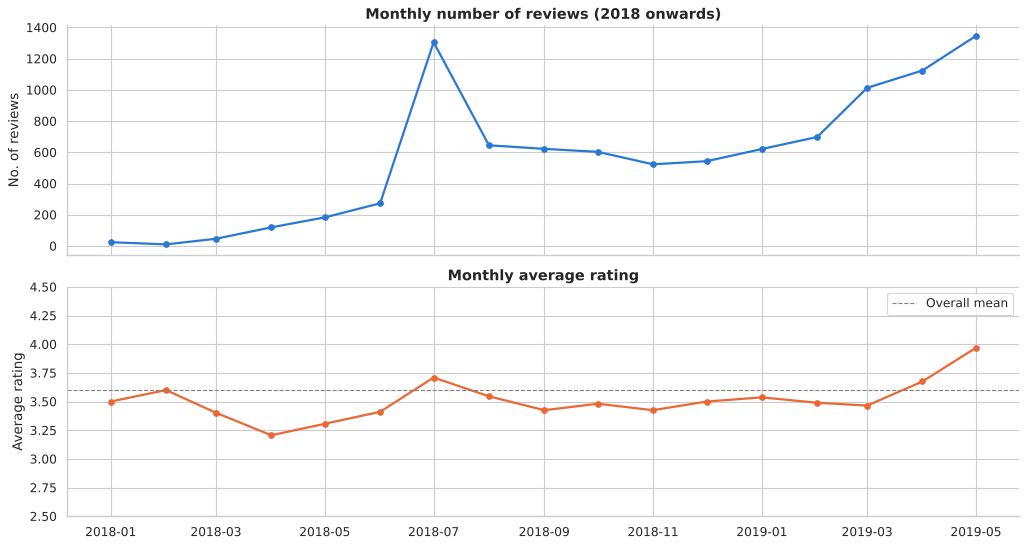

Reviews per year: {2016: 43, 2017: 213, 2018: 4896, 2019: 4802}


In [22]:
# Chart - 9 visualization code : Review volume and rating over time (Bivariate: time - numerical)
monthly = (reviews.dropna(subset=['Time']).set_index('Time').resample('MS')
           .agg({'Rating': ['size', 'mean']}))
monthly.columns = ['n_reviews', 'avg_rating']
monthly = monthly[monthly.index >= '2018-01-01']       # 2016-17 has very few reviews
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(monthly.index, monthly['n_reviews'], color=BLUE, lw=2, marker='o', ms=5)
axes[0].set(title='Monthly number of reviews (2018 onwards)', ylabel='No. of reviews')
axes[1].plot(monthly.index, monthly['avg_rating'], color=ORANGE, lw=2, marker='o', ms=5)
axes[1].axhline(reviews['Rating'].mean(), color='grey', ls='--', lw=1, label='Overall mean')
axes[1].set(title='Monthly average rating', ylabel='Average rating', ylim=(2.5, 4.5))
axes[1].legend()
plt.tight_layout()
plt.show()
print('Reviews per year:', reviews['Year'].value_counts().sort_index().to_dict())

##### 1. Why did you pick the specific chart?

**Line charts** are the best way to show change over time. I used **two separate panels with their own y-axes** (volume and average rating) instead of a dual-axis chart, so neither measure distorts the other.

##### 2. What is/are the insight(s) found from the chart?

* Reviews grow sharply from 2018 (2016–17 have only 256 reviews in total). There is a **spike in July 2018 (~1,300 reviews)** and steady growth through early 2019, reaching ~1,350 in May 2019.
* The monthly average rating dipped to **~3.2 in April 2018** and recovered to **~4.0 by May 2019**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** platform engagement and customer satisfaction are both rising, which is a healthy growth trend. **Negative:** the early-2018 dip shows that satisfaction can drop when activity ramps up quickly (e.g. more orders but service not scaling). Zomato should watch quality metrics during growth spikes.

#### Chart - 10

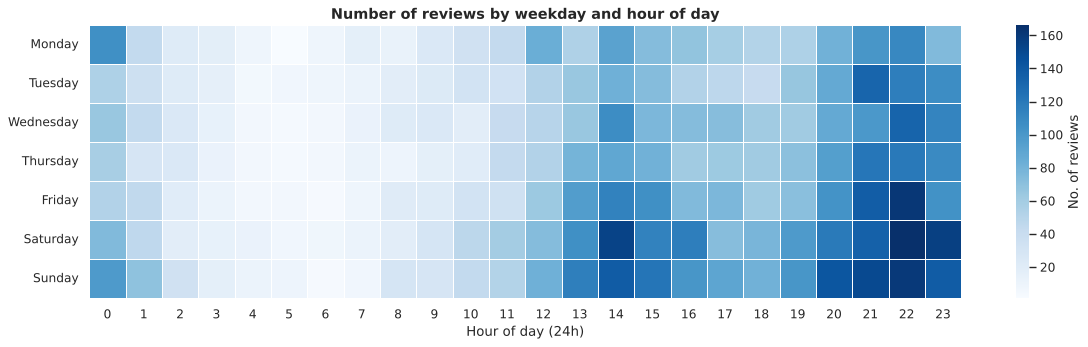

Busiest review hours: {22: 967, 21: 875, 23: 802}
Reviews by weekday  : {'Monday': 1244, 'Tuesday': 1192, 'Wednesday': 1282, 'Thursday': 1243, 'Friday': 1432, 'Saturday': 1736, 'Sunday': 1825}


In [23]:
# Chart - 10 visualization code : When do people post reviews? (Hour x Weekday heatmap - Multivariate)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heat = reviews.pivot_table(index='Weekday', columns='Hour', values='Rating', aggfunc='size').reindex(day_order).fillna(0)
plt.figure(figsize=(15, 4.5))
sns.heatmap(heat, cmap='Blues', linewidths=0.5, linecolor='white', cbar_kws={'label': 'No. of reviews'})
plt.title('Number of reviews by weekday and hour of day')
plt.xlabel('Hour of day (24h)')
plt.ylabel('')
plt.tight_layout()
plt.show()
print('Busiest review hours:', reviews['Hour'].value_counts().head(3).to_dict())
print('Reviews by weekday  :', reviews['Weekday'].value_counts().reindex(day_order).to_dict())

##### 1. Why did you pick the specific chart?

A **heatmap** encodes a third variable (number of reviews) on a two-dimensional grid (weekday × hour), so peak times are visible immediately. This is a multivariate view.

##### 2. What is/are the insight(s) found from the chart?

* Reviews peak **between 9 PM and 11 PM** (22:00 is the busiest hour, with 967 reviews), right after dinner. There is a second peak at **1–3 PM** after lunch.
* **Saturday (1,736) and Sunday (1,825)** have the most reviews, about 36% of all reviews.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Zomato can time **review-request notifications** and **promotions** for weekend evenings, when users are most active, and restaurants can staff up for the dinner rush. No negative growth insight, but very few reviews between 3 AM and 9 AM means late-night offers have a small audience.

#### Chart - 11

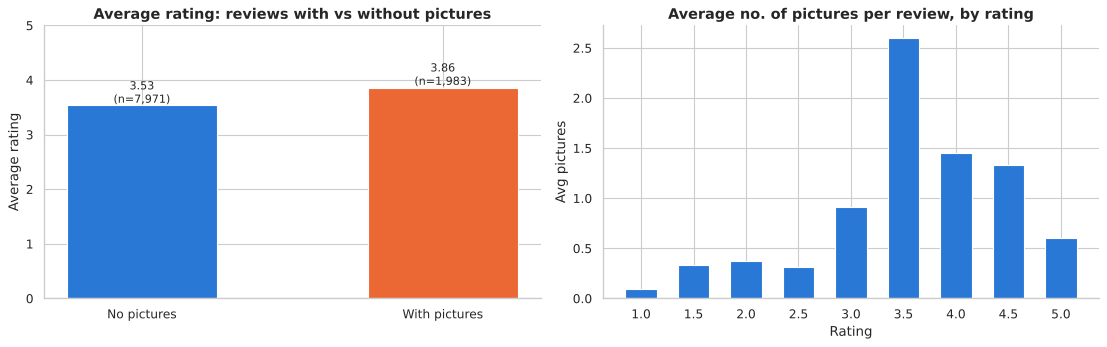

In [24]:
# Chart - 11 visualization code : Do reviews with pictures rate differently? (Bivariate: categorical - numerical)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pic_rating = reviews.groupby('has_pictures')['Rating'].agg(['mean', 'size']).rename(index={0: 'No pictures', 1: 'With pictures'})
axes[0].bar(pic_rating.index, pic_rating['mean'], color=[BLUE, ORANGE], width=0.5)
for x, (m, n) in enumerate(zip(pic_rating['mean'], pic_rating['size'])):
    axes[0].text(x, m + 0.05, f'{m:.2f}\n(n={n:,})', ha='center', fontsize=10)
axes[0].set(title='Average rating: reviews with vs without pictures', ylabel='Average rating', ylim=(0, 5))
pics_by_rating = reviews.groupby('Rating')['Pictures'].mean()
axes[1].bar(pics_by_rating.index.astype(str), pics_by_rating.values, color=BLUE, width=0.6)
axes[1].set(title='Average no. of pictures per review, by rating', xlabel='Rating', ylabel='Avg pictures')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A **bar chart of means** compares two groups (with vs without pictures), and the second bar chart shows how picture-posting changes across ratings.

##### 2. What is/are the insight(s) found from the chart?

* Only **~20% of reviews include pictures**, but these reviews have a **higher average rating (3.86 vs 3.53)**.
* Pictures are posted mostly with **3.5–4.5★** reviews. Angry 1★ reviewers rarely post photos.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** photo reviews are generally favourable and make a listing look more attractive. Zomato could reward users for posting photos (e.g. Zomato points). **Caution:** photo reviews are biased towards positive experiences, so photos alone should not be used to judge a restaurant.

#### Chart - 12

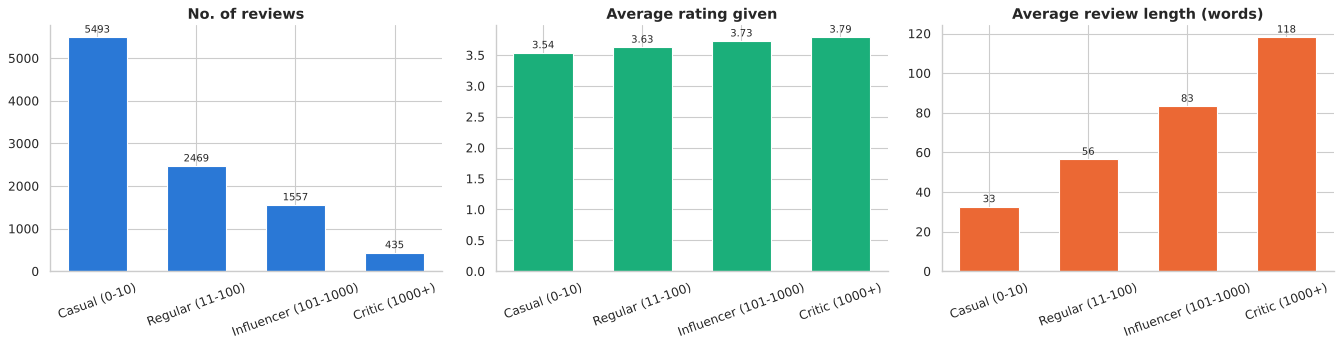

,n_reviews,avg_rating,pct_negative,avg_length
Reviewer_type,,,,
Casual (0-10),5493,3.54,30.33,32.56
Regular (11-100),2469,3.63,21.67,56.49
Influencer (101-1000),1557,3.73,12.78,83.28
Critic (1000+),435,3.79,10.80,118.18


,followers,reviews_here,avg_rating
Reviewer,,,
Satwinder Singh,13410,3,3.67
Eat_vth_me,13320,1,5.00
Samar Sardar,11329,2,3.50
Foodies Hyderabad,9494,4,4.50
Srinivas,7628,7,3.71
Aman Arora,7589,1,4.00
ASH&B2,6931,3,3.33
Hasanthi Mula,5879,1,3.00
#FOODPORN,5873,1,5.00


In [25]:
# Chart - 12 visualization code : Critics vs regular reviewers (Bivariate: categorical - numerical)
reviews['Reviewer_type'] = pd.cut(reviews['reviewer_followers'], bins=[-1, 10, 100, 1000, np.inf],
                                  labels=['Casual (0-10)', 'Regular (11-100)', 'Influencer (101-1000)', 'Critic (1000+)'])
grp = reviews.groupby('Reviewer_type', observed=True).agg(
    n_reviews=('Rating', 'size'), avg_rating=('Rating', 'mean'),
    pct_negative=('Sentiment', lambda s: (s == 'Negative').mean() * 100),
    avg_length=('review_length', 'mean'))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title, color in [(axes[0], 'n_reviews', 'No. of reviews', BLUE),
                              (axes[1], 'avg_rating', 'Average rating given', AQUA),
                              (axes[2], 'avg_length', 'Average review length (words)', ORANGE)]:
    ax.bar(grp.index.astype(str), grp[col], color=color, width=0.6)
    ax.bar_label(ax.containers[0], fmt='%.2f' if col == 'avg_rating' else '%.0f', padding=2, fontsize=9)
    ax.set(title=title)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()
display(grp.round(2))
# Top critics in the data set (most followers)
critics = (reviews.groupby('Reviewer').agg(followers=('reviewer_followers', 'max'),
                                            reviews_here=('Rating', 'size'), avg_rating=('Rating', 'mean'))
           .sort_values('followers', ascending=False).head(10).round(2))
display(critics)

##### 1. Why did you pick the specific chart?

**Three bar charts side by side** compare reviewer groups (based on follower count) on volume, rating and review length. A table of the top critics is added for identification, since the brief mentions *identifying the critics in the industry*.

##### 2. What is/are the insight(s) found from the chart?

* **55% of reviews come from casual users (0–10 followers)**. Only 435 reviews (4%) come from **critics with 1,000+ followers**.
* Critics write **~3.6× longer reviews (118 vs 33 words)** and are **less negative** (10.8% vs 30.3% negative reviews). Their average rating is slightly higher (3.79 vs 3.54).
* The top critics include *Satwinder Singh* (13,410 followers), *Eat_vth_me* and *Samar Sardar*.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** critics have a large reach and write detailed, balanced reviews, so Zomato and restaurants can invite them to tastings and launch events. **Negative:** most harsh ratings come from casual users, who are the bulk of the customer base. Ignoring their complaints (e.g. delivery delays, cold food) would hurt ratings the most.

#### Chart - 13

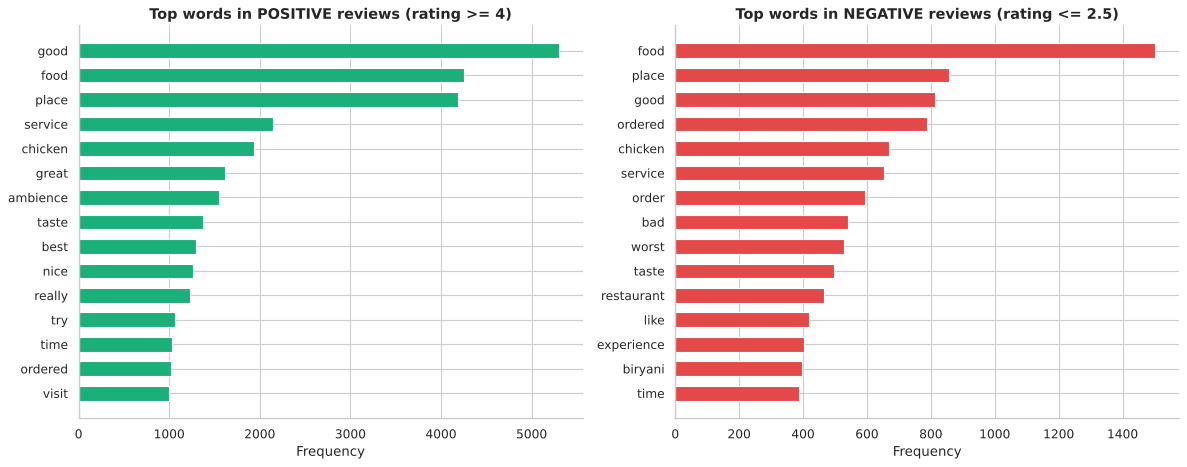

In [26]:
# Chart - 13 visualization code : Most frequent words in positive vs negative reviews (Bivariate: categorical - text)
def top_words(texts, n=15):
    """Return the n most frequent meaningful words (English stop-words removed)."""
    cv = CountVectorizer(stop_words='english', token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')
    counts = np.asarray(cv.fit_transform(texts).sum(axis=0)).ravel()
    return pd.Series(counts, index=cv.get_feature_names_out()).nlargest(n)

pos_words = top_words(reviews.loc[reviews['Sentiment'] == 'Positive', 'Review'])
neg_words = top_words(reviews.loc[reviews['Sentiment'] == 'Negative', 'Review'])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(pos_words.index[::-1], pos_words.values[::-1], color=AQUA, height=0.6)
axes[0].set(title='Top words in POSITIVE reviews (rating >= 4)', xlabel='Frequency')
axes[1].barh(neg_words.index[::-1], neg_words.values[::-1], color=PALETTE[7], height=0.6)
axes[1].set(title='Top words in NEGATIVE reviews (rating <= 2.5)', xlabel='Frequency')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

**Side-by-side horizontal bar charts** compare the most frequent words in positive and negative reviews. It is a readable, quantitative alternative to a word cloud.

##### 2. What is/are the insight(s) found from the chart?

* **Positive reviews:** *good, food, place, service, great, ambience, taste, best, nice*. Happy customers talk about **ambience and service** along with food.
* **Negative reviews:** *food, ordered, order, bad, worst, taste, experience, time*. Unhappy customers talk about **orders/delivery, taste and waiting time**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** ambience and service are clear drivers of good ratings, so restaurants should invest in staff behaviour (positive reviews often mention waiters by name). **Negative:** words like *ordered / order / time* in negative reviews point to **online-order and delivery problems**, an area where Zomato itself is responsible. Fixing delivery time and packaging directly reduces negative reviews.

#### Chart - 14 - Correlation Heatmap

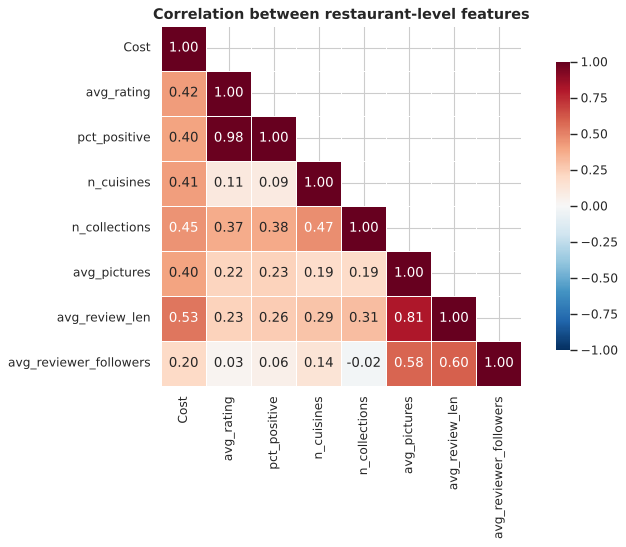

In [27]:
# Correlation Heatmap visualization code (Multivariate)
num_cols = ['Cost', 'avg_rating', 'pct_positive', 'n_cuisines', 'n_collections',
            'avg_pictures', 'avg_review_len', 'avg_reviewer_followers']
corr = restaurants[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)       # show lower triangle only
plt.figure(figsize=(10, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation between restaurant-level features')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A **correlation heatmap** summarises the pairwise linear relationships between all numeric restaurant-level features in one view. It helps spot **multicollinearity** before building the clustering features. Only the lower triangle is shown to avoid repeating values, and a diverging red/blue colour scale centred at 0 separates positive from negative correlation.

##### 2. What is/are the insight(s) found from the chart?

* **avg_rating ↔ pct_positive: r = 0.98.** They measure the same thing, so one must be dropped before clustering.
* **avg_pictures ↔ avg_review_len: r = 0.81.** Detailed reviewers also post photos, so this pair is redundant too.
* **Cost correlates moderately with everything** (rating 0.42, n_cuisines 0.41, n_collections 0.45, review length 0.53). Expensive places serve more cuisines, are featured in more collections and get more detailed reviews.
* **avg_reviewer_followers** is related to review length and pictures (~0.6) but not to rating (0.03). Influencers don't rate differently, they just write more.

#### Chart - 15 - Pair Plot

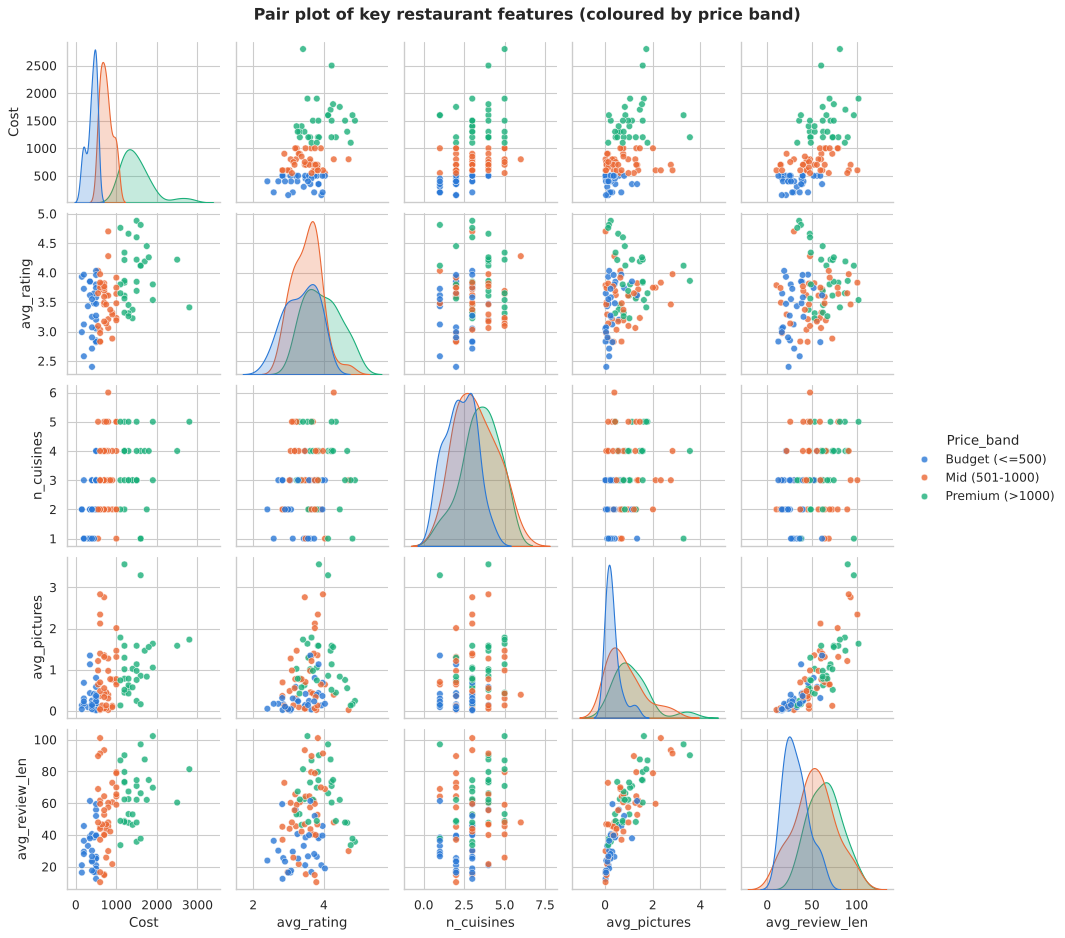

In [28]:
# Pair Plot visualization code (Multivariate)
pair_cols = ['Cost', 'avg_rating', 'n_cuisines', 'avg_pictures', 'avg_review_len']
g = sns.pairplot(restaurants.dropna(subset=['avg_rating']), vars=pair_cols, hue='Price_band',
                 palette=PALETTE[:3], diag_kind='kde', plot_kws={'s': 35, 'alpha': 0.8, 'edgecolor': 'white'},
                 height=2.3)
g.figure.suptitle('Pair plot of key restaurant features (coloured by price band)', y=1.02, fontweight='bold')
plt.show()

##### 1. Why did you pick the specific chart?

A **pair plot** shows every pairwise scatter plot plus each feature's distribution (KDE on the diagonal) in a single grid. Colouring by **price band** adds a third dimension, so it is a quick multivariate check of whether the price segments separate naturally.

##### 2. What is/are the insight(s) found from the chart?

* **Premium restaurants (green) sit higher on avg_rating** and have longer reviews and more pictures. Budget (blue) restaurants cluster at lower ratings and shorter reviews.
* The rating KDE shows that the Mid band is tightly concentrated around 3.5, while Premium is spread towards 4–5.
* Price bands overlap heavily on *n_cuisines*, so price alone does not explain the menu variety. A multi-feature clustering is needed to find real segments.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the charts, I defined three hypotheses:

1. **Cost vs rating (Chart 7):** restaurants that charge more get better ratings, i.e. cost for two and average rating are related.
2. **Pictures vs rating (Chart 11):** reviews posted with pictures have different (higher) ratings than reviews without pictures.
3. **Price band vs sentiment (Charts 6, 7):** the share of positive/negative reviews depends on the restaurant's price band.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null hypothesis (H₀):** There is no monotonic relationship between cost for two and the restaurant's average rating (Spearman ρ = 0).
* **Alternate hypothesis (H₁):** There is a monotonic relationship between cost for two and average rating (ρ ≠ 0).
* Significance level α = 0.05.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
# H0: There is no monotonic relationship between cost for two and average rating (rho = 0)
# H1: There is a monotonic relationship between cost for two and average rating (rho != 0)
ALPHA = 0.05
h1_data = restaurants.dropna(subset=['avg_rating'])
rho, p_value = stats.spearmanr(h1_data['Cost'], h1_data['avg_rating'])
print(f'Spearman rho = {rho:.3f} | p-value = {p_value:.4f} | n = {len(h1_data)}')
print('Decision:', 'Reject H0 -> cost and rating ARE related' if p_value < ALPHA
      else 'Fail to reject H0 -> no significant relationship')

Spearman rho = 0.384 | p-value = 0.0001 | n = 100
Decision: Reject H0 -> cost and rating ARE related


##### Which statistical test have you done to obtain P-Value?

**Spearman rank correlation test.** Result: ρ = 0.384, **p-value = 0.0001 < 0.05 → reject H₀**. Cost and rating are significantly (and positively) related. Customers do perceive more expensive restaurants as better, but ρ = 0.38 means that price explains only part of the rating.

##### Why did you choose the specific statistical test?

* Both variables are numeric, and I want to test **association**, not a difference between groups.
* `Cost` is skewed (skew 1.14) with outliers, and only 100 restaurants have ratings, so the normality assumption of the Pearson test is doubtful. **Spearman is non-parametric**: it works on ranks, is robust to outliers and detects any monotonic (not only linear) relationship.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null hypothesis (H₀):** The rating distribution of reviews **with** pictures is the same as that of reviews **without** pictures.
* **Alternate hypothesis (H₁):** The two rating distributions are different.
* Significance level α = 0.05.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
# H0: Ratings of reviews WITH pictures and WITHOUT pictures come from the same distribution
# H1: The two groups have different rating distributions
with_pics = reviews.loc[reviews['has_pictures'] == 1, 'Rating']
without_pics = reviews.loc[reviews['has_pictures'] == 0, 'Rating']
u_stat, p_value = stats.mannwhitneyu(with_pics, without_pics, alternative='two-sided')
print(f'Median rating with pictures = {with_pics.median()} | without = {without_pics.median()}')
print(f'Mean rating   with pictures = {with_pics.mean():.2f} | without = {without_pics.mean():.2f}')
print(f'Mann-Whitney U = {u_stat:,.0f} | p-value = {p_value:.2e}')
print('Decision:', 'Reject H0 -> ratings differ' if p_value < ALPHA else 'Fail to reject H0')

Median rating with pictures = 4.0 | without = 4.0
Mean rating   with pictures = 3.86 | without = 3.53
Mann-Whitney U = 8,238,286 | p-value = 2.32e-03
Decision: Reject H0 -> ratings differ


##### Which statistical test have you done to obtain P-Value?

**Mann-Whitney U test (two-sided).** Result: U = 8,238,286, **p-value = 0.0023 < 0.05 → reject H₀**. Reviews with pictures have significantly different ratings (mean 3.86 vs 3.53). Both groups have a median of 4, but the with-pictures group has fewer low ratings.

##### Why did you choose the specific statistical test?

* We compare **one numeric variable (rating) across two independent groups**.
* Rating is **ordinal** (1–5 stars in steps of 0.5) and heavily non-normal (polarised at 1 and 5), so an independent t-test's normality assumption does not hold. The **Mann-Whitney U test** is the non-parametric alternative: it compares the rank distributions of the two groups and makes no normality assumption.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null hypothesis (H₀):** Review sentiment (Positive / Neutral / Negative) is **independent** of the restaurant's price band (Budget / Mid / Premium).
* **Alternate hypothesis (H₁):** Review sentiment **depends on** the price band.
* Significance level α = 0.05.

#### 2. Perform an appropriate statistical test.

In [31]:
# Perform Statistical Test to obtain P-Value
# H0: Review sentiment is independent of the restaurant's price band
# H1: Review sentiment depends on the price band
rev_price = reviews.merge(restaurants[['Name', 'Price_band']], left_on='Restaurant', right_on='Name', how='left')
contingency = pd.crosstab(rev_price['Price_band'], rev_price['Sentiment'])
chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
display(contingency)
display((pd.crosstab(rev_price['Price_band'], rev_price['Sentiment'], normalize='index') * 100).round(1))
print(f'Chi-square = {chi2:.2f} | dof = {dof} | p-value = {p_value:.2e}')
print('Decision:', 'Reject H0 -> sentiment depends on price band' if p_value < ALPHA else 'Fail to reject H0')

Sentiment,Negative,Neutral,Positive
Price_band,,,
Budget (<=500),971,345,1680
Mid (501-1000),987,539,2347
Premium (>1000),489,355,2241


Sentiment,Negative,Neutral,Positive
Price_band,,,
Budget (<=500),32.4,11.5,56.1
Mid (501-1000),25.5,13.9,60.6
Premium (>1000),15.9,11.5,72.6


Chi-square = 254.53 | dof = 4 | p-value = 6.87e-54
Decision: Reject H0 -> sentiment depends on price band


##### Which statistical test have you done to obtain P-Value?

**Chi-square test of independence** on a 3 × 3 contingency table. Result: χ² = 254.5, dof = 4, **p-value ≈ 6.9e-54 < 0.05 → reject H₀**. Sentiment clearly depends on price band: **negative reviews fall from 32.4% (Budget) to 25.5% (Mid) to 15.9% (Premium)**, and positive reviews rise from 56.1% to 72.6%.

##### Why did you choose the specific statistical test?

* Both variables are **categorical** (price band and sentiment class), and the question is whether they are associated.
* The **Chi-square test of independence** is the standard test for this. All expected cell counts are far above 5 (thousands of reviews), so its assumptions are satisfied.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [32]:
# Handling Missing Values & Missing Value Imputation
# 1) Metadata: Collections (54 missing) -> it simply means "not part of any Zomato collection"
restaurants['Collections'] = restaurants['Collections'].fillna('No Collection')
# 2) Metadata: Timings (1 missing) -> categorical constant
restaurants['Timings'] = restaurants['Timings'].fillna('Not Available')
# 3) 5 restaurants have no reviews -> review based features are missing.
#    Impute with the MEDIAN (robust to skew) and keep a flag so the information is not lost.
review_feats = ['avg_rating', 'pct_positive', 'avg_pictures', 'avg_review_len', 'avg_reviewer_followers']
restaurants['no_reviews_flag'] = restaurants['avg_rating'].isna().astype(int)
restaurants['n_reviews'] = restaurants['n_reviews'].fillna(0)
for col in review_feats:
    restaurants[col] = restaurants[col].fillna(restaurants[col].median())
# 4) Reviews: rows with missing rating/review were already dropped in wrangling (only 0.5% of rows);
#    missing reviewer metadata was converted to 0 reviews / 0 followers.
print('Missing values left in restaurant table:', int(restaurants[review_feats + ['Cost']].isna().sum().sum()))
print('Missing values left in review table   :', int(reviews[['Rating', 'Review']].isna().sum().sum()))

Missing values left in restaurant table: 0
Missing values left in review table   : 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

| Column | Missing | Technique | Why |
|---|---|---|---|
| Collections | 54 / 105 | Constant **"No Collection"** + `n_collections = 0` | Missing means *not tagged*, which is information in itself, not an error |
| Timings | 1 | Constant **"Not Available"** | Only 1 row and not used for modelling |
| Review-based features (avg_rating, pct_positive, …) | 5 restaurants with no reviews | **Median imputation** + `no_reviews_flag` | The median is robust to skew/outliers, and the flag keeps the fact that the value was imputed |
| Reviews: blank duplicates, Rating / Review text | 46 rows (0.46%, incl. 36 blank duplicates) | **Row deletion** | Rating and text are the core signals for sentiment, and imputing a review text is meaningless. Losing <0.5% of rows has no impact |
| Reviewer metadata | blank rows | Parsed as **0 reviews / 0 followers** | These rows were removed anyway |

### 2. Handling Outliers

,feature,lower_fence,upper_fence,n_outliers
0,Cost,-550.00,2250.00,2
1,avg_rating,2.38,4.72,3
2,avg_pictures,-1.15,2.37,4
3,avg_review_len,-6.98,106.94,0
4,avg_reviewer_followers,-96.45,410.23,4


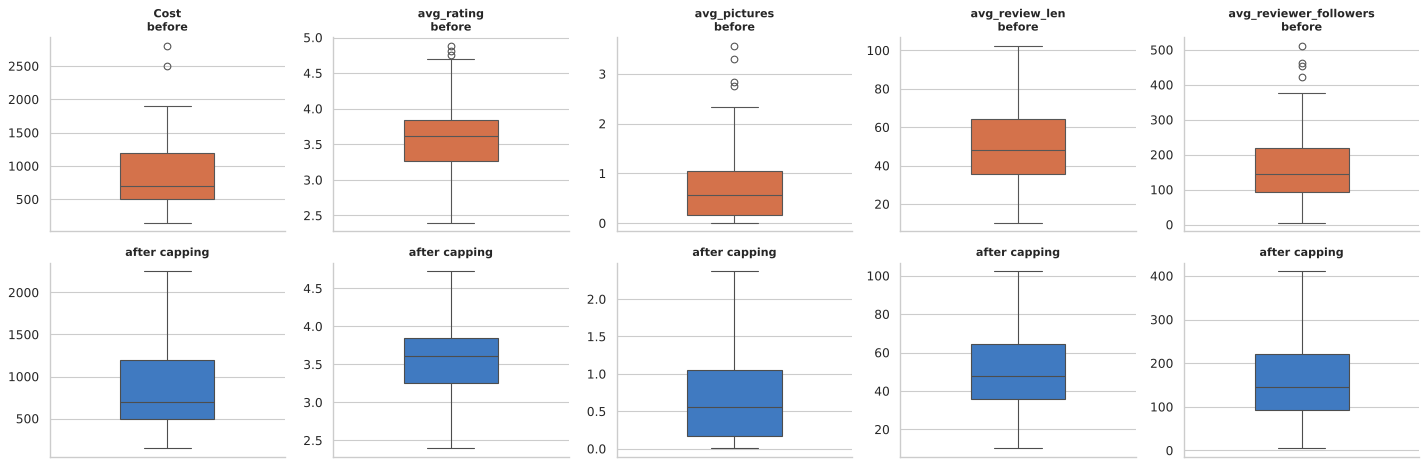

In [33]:
# Handling Outliers & Outlier treatments
def iqr_bounds(s: pd.Series, k: float = 1.5):
    """Return lower/upper IQR fences."""
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)


outlier_cols = ['Cost', 'avg_rating', 'avg_pictures', 'avg_review_len', 'avg_reviewer_followers']
summary = []
for col in outlier_cols:
    lo, hi = iqr_bounds(restaurants[col])
    n_out = int(((restaurants[col] < lo) | (restaurants[col] > hi)).sum())
    summary.append({'feature': col, 'lower_fence': round(lo, 2), 'upper_fence': round(hi, 2), 'n_outliers': n_out})
display(pd.DataFrame(summary))

# Treatment: cap (winsorise) at the IQR fences instead of deleting rows.
# With only 105 restaurants, every row is a real business - we do not want to drop any.
restaurants_capped = restaurants.copy()
for col in outlier_cols:
    lo, hi = iqr_bounds(restaurants[col])
    restaurants_capped[col] = restaurants[col].clip(lower=lo, upper=hi)

fig, axes = plt.subplots(2, len(outlier_cols), figsize=(18, 6))
for i, col in enumerate(outlier_cols):
    sns.boxplot(y=restaurants[col], ax=axes[0, i], color=ORANGE, width=0.4)
    sns.boxplot(y=restaurants_capped[col], ax=axes[1, i], color=BLUE, width=0.4)
    axes[0, i].set_title(f'{col}\nbefore', fontsize=10)
    axes[1, i].set_title('after capping', fontsize=10)
    axes[0, i].set_ylabel(''); axes[1, i].set_ylabel('')
plt.tight_layout()
plt.show()
# NOTE: Review-level outliers (very long reviews, 64 pictures) are genuine customer behaviour,
# so they are kept for text analysis.

##### What all outlier treatment techniques have you used and why did you use those techniques?

* **Detection:** IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR). Found 2 outliers in Cost (the Rs 2,500 / 2,800 hotel restaurants), 3 in avg_rating, 4 in avg_pictures and 4 in avg_reviewer_followers.
* **Treatment: capping (winsorisation) at the IQR fences** instead of deleting rows. With only 105 restaurants, every row is a real business that must get a cluster, so deletion is not acceptable. Capping keeps the row while stopping extreme values from pulling the K-Means centroids (K-Means uses means and squared distances, so it is very sensitive to outliers).
* Review-level extremes (64 pictures, 1,000+ word reviews) are genuine customer behaviour, so they were **kept** for the text analysis.
* Remaining skew was handled later with a log transform.

### 3. Categorical Encoding

In [34]:
# Encode your categorical columns
# Cuisines is a MULTI-LABEL column (one restaurant -> many cuisines) -> MultiLabelBinarizer (one-hot per cuisine)
mlb = MultiLabelBinarizer()
cuisine_dummies = pd.DataFrame(mlb.fit_transform(restaurants['Cuisine_list']),
                               columns=['cuisine_' + c.replace(' ', '_') for c in mlb.classes_],
                               index=restaurants.index)
print('Cuisine one-hot matrix:', cuisine_dummies.shape)

# Price band is ORDINAL -> simple ordered integer encoding (used for profiling)
restaurants['price_band_code'] = restaurants['Price_band'].cat.codes

# Sentiment target for the review classifier (binary, neutral reviews kept aside)
reviews['target'] = reviews['Sentiment'].map({'Positive': 1, 'Negative': 0})
print('Price band codes :', dict(enumerate(restaurants['Price_band'].cat.categories)))
print('Sentiment target :', reviews['target'].value_counts(dropna=False).to_dict(), '(NaN = neutral)')
cuisine_dummies.head()

Cuisine one-hot matrix: (105, 44)
Price band codes : {0: 'Budget (<=500)', 1: 'Mid (501-1000)', 2: 'Premium (>1000)'}
Sentiment target : {1.0: 6268, 0.0: 2447, nan: 1239} (NaN = neutral)


,cuisine_American,cuisine_Andhra,cuisine_Arabian,cuisine_Asian,cuisine_BBQ,cuisine_Bakery,cuisine_Beverages,cuisine_Biryani,cuisine_Burger,cuisine_Cafe,cuisine_Chinese,cuisine_Continental,cuisine_Desserts,cuisine_European,cuisine_Fast_Food,cuisine_Finger_Food,cuisine_Goan,cuisine_Healthy_Food,cuisine_Hyderabadi,cuisine_Ice_Cream,cuisine_Indonesian,cuisine_Italian,cuisine_Japanese,cuisine_Juices,cuisine_Kebab,cuisine_Lebanese,cuisine_Malaysian,cuisine_Mediterranean,cuisine_Mexican,cuisine_Mithai,cuisine_Modern_Indian,cuisine_Momos,cuisine_Mughlai,cuisine_North_Eastern,cuisine_North_Indian,cuisine_Pizza,cuisine_Salad,cuisine_Seafood,cuisine_South_Indian,cuisine_Spanish,cuisine_Street_Food,cuisine_Sushi,cuisine_Thai,cuisine_Wraps
0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0
1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


#### What all categorical encoding techniques have you used & why did you use those techniques?

* **`Cuisines` → MultiLabelBinarizer** (one-hot per cuisine, 44 columns). A restaurant can serve several cuisines, so normal one-hot or label encoding is not possible. These dummies were then summarised into **5 cuisine-family share features** (see feature manipulation) to avoid 44 sparse columns.
* **`Price_band` → ordinal integer encoding (0, 1, 2)**, because Budget < Mid < Premium has a natural order.
* **`Sentiment` → binary target (Positive = 1, Negative = 0)** for the classifier. Neutral reviews are left out of training, because their mixed text would add label noise.
* Name, Links and Timings are identifiers / free text and were **not encoded** (no clustering signal).

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [35]:
# Expand Contraction
CONTRACTIONS = {
    "won't": "will not", "can't": "can not", "n't": " not", "'re": " are", "'s": " is", "'d": " would",
    "'ll": " will", "'ve": " have", "'m": " am", "dont": "do not", "didnt": "did not", "doesnt": "does not",
    "isnt": "is not", "wasnt": "was not", "wont": "will not", "cant": "can not", "couldnt": "could not",
    "wouldnt": "would not", "shouldnt": "should not", "havent": "have not", "im": "i am", "ive": "i have"}
_contraction_re = re.compile(r"\b(" + "|".join(sorted([re.escape(k) for k in CONTRACTIONS if "'" not in k], key=len, reverse=True)) + r")\b")


def expand_contractions(text: str) -> str:
    """Expand english contractions (with and without apostrophe)."""
    text = text.replace('’', "'")                 # curly apostrophe -> straight
    text = text.replace("won't", "will not").replace("can't", "can not")
    for k in ["n't", "'re", "'s", "'d", "'ll", "'ve", "'m"]:
        text = text.replace(k, CONTRACTIONS[k])
    return _contraction_re.sub(lambda m: CONTRACTIONS[m.group(0)], text)


text_df = reviews[['Restaurant', 'Review', 'Rating', 'Sentiment', 'target']].copy()
text_df['clean_review'] = text_df['Review'].apply(expand_contractions)
has_contraction = text_df['Review'].str.contains("n't", regex=False)
example_idx = text_df.loc[has_contraction, 'Review'].str.len().idxmin()     # shortest review with a contraction
print('Before :', text_df.loc[example_idx, 'Review'][:200])
print('After  :', text_df.loc[example_idx, 'clean_review'][:200])

Before : didn't deliver
After  : did not deliver


#### 2. Lower Casing

In [36]:
# Lower Casing
text_df['clean_review'] = text_df['clean_review'].str.lower()
text_df['clean_review'].head(3).tolist()

['the ambience was good, food was quite good . had saturday lunch , which was cost effective .\ngood place for a sate brunch. one can also chill with friends and or parents.\nwaiter soumen das was really courteous and helpful.', 'ambience is too good for a pleasant evening. service is very prompt. food is good. over all a good experience. soumen das - kudos to the service', 'a must try.. great food great ambience. thnx for the service by pradeep and subroto. my personal recommendation is penne alfredo pasta:) ....... also the music in the background is amazing.']

#### 3. Removing Punctuations

In [37]:
# Remove Punctuations
URL_RE = re.compile(r'http\S+|www\.\S+')
PUNCT_TABLE = str.maketrans({p: ' ' for p in string.punctuation})   # replace with space, not ''


def remove_punctuation(text: str) -> str:
    text = URL_RE.sub(' ', text)        # URLs are removed FIRST, otherwise punctuation removal breaks them apart
    return text.translate(PUNCT_TABLE)

text_df['clean_review'] = text_df['clean_review'].apply(remove_punctuation)
text_df['clean_review'].head(3).tolist()

['the ambience was good  food was quite good   had saturday lunch   which was cost effective  \ngood place for a sate brunch  one can also chill with friends and or parents \nwaiter soumen das was really courteous and helpful ', 'ambience is too good for a pleasant evening  service is very prompt  food is good  over all a good experience  soumen das   kudos to the service', 'a must try   great food great ambience  thnx for the service by pradeep and subroto  my personal recommendation is penne alfredo pasta           also the music in the background is amazing ']

#### 4. Removing URLs & Removing words and digits contain digits.

In [38]:
# Remove URLs & Remove words and digits contain digits
def remove_urls_digits(text: str) -> str:
    text = URL_RE.sub(' ', text)                        # any URL left over (safety net)
    text = re.sub(r'\w*\d\w*', ' ', text)               # words containing digits e.g. 2nd, 500rs
    text = re.sub(r'[^a-z\s]', ' ', text)               # emojis / non-english characters
    return text

text_df['clean_review'] = text_df['clean_review'].apply(remove_urls_digits)
text_df['clean_review'].head(3).tolist()

['the ambience was good  food was quite good   had saturday lunch   which was cost effective  \ngood place for a sate brunch  one can also chill with friends and or parents \nwaiter soumen das was really courteous and helpful ', 'ambience is too good for a pleasant evening  service is very prompt  food is good  over all a good experience  soumen das   kudos to the service', 'a must try   great food great ambience  thnx for the service by pradeep and subroto  my personal recommendation is penne alfredo pasta           also the music in the background is amazing ']

#### 5. Removing Stopwords & Removing White spaces

In [39]:
# Remove Stopwords
# Start from scikit-learn's English stop-word list BUT keep negations,
# because "not good" and "good" carry opposite sentiment.
NEGATIONS = {'no', 'not', 'nor', 'never', 'none', 'nothing', 'nobody', 'cannot', 'without'}
STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATIONS
text_df['clean_review'] = text_df['clean_review'].apply(
    lambda t: ' '.join(w for w in t.split() if w not in STOP_WORDS))
print('Stop-words used:', len(STOP_WORDS))
text_df['clean_review'].head(3).tolist()

Stop-words used: 309


['ambience good food quite good saturday lunch cost effective good place sate brunch chill friends parents waiter soumen das really courteous helpful', 'ambience good pleasant evening service prompt food good good experience soumen das kudos service', 'try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music background amazing']

In [40]:
# Remove White spaces (multiple spaces / leading / trailing)
text_df['clean_review'] = text_df['clean_review'].str.replace(r'\s+', ' ', regex=True).str.strip()
print('Empty reviews after cleaning:', (text_df['clean_review'] == '').sum())

Empty reviews after cleaning: 22


#### 6. Rephrase Text

In [41]:
# Rephrase Text
# Reviews contain a lot of SMS-style slang / repeated letters ("gud", "awsm", "sooooo").
# Normalise them to standard English so that the vectoriser treats them as the same word.
SLANG = {'gud': 'good', 'gd': 'good', 'nyc': 'nice', 'awsm': 'awesome', 'awsome': 'awesome',
         'thnx': 'thanks', 'thanx': 'thanks', 'thx': 'thanks', 'plz': 'please', 'pls': 'please',
         'yummy': 'tasty', 'ambiance': 'ambience', 'servise': 'service',
         'resturant': 'restaurant', 'restaraunt': 'restaurant', 'u': 'you',
         'ur': 'your', 'bcoz': 'because', 'coz': 'because', 'veg': 'vegetarian', 'nonveg': 'non vegetarian'}


def rephrase(text: str) -> str:
    text = re.sub(r'(\w)\1{2,}', r'\1\1', text)          # sooooo -> soo, gooood -> good
    return ' '.join(SLANG.get(w, w) for w in text.split())

text_df['clean_review'] = text_df['clean_review'].apply(rephrase)
text_df['clean_review'].head(3).tolist()

['ambience good food quite good saturday lunch cost effective good place sate brunch chill friends parents waiter soumen das really courteous helpful', 'ambience good pleasant evening service prompt food good good experience soumen das kudos service', 'try great food great ambience thanks service pradeep subroto personal recommendation penne alfredo pasta music background amazing']

#### 7. Tokenization

In [42]:
# Tokenization (simple and fast word tokenizer on the cleaned text)
text_df['tokens'] = text_df['clean_review'].str.split()
text_df['n_tokens'] = text_df['tokens'].str.len()
print('Average tokens per review after cleaning:', round(text_df['n_tokens'].mean(), 1))
text_df[['clean_review', 'tokens']].head(3)

Average tokens per review after cleaning: 25.7


,clean_review,tokens
0,ambience good food quite good saturday lunch c...,"[ambience, good, food, quite, good, saturday, ..."
1,ambience good pleasant evening service prompt ...,"[ambience, good, pleasant, evening, service, p..."
2,try great food great ambience thanks service p...,"[try, great, food, great, ambience, thanks, se..."


#### 8. Text Normalization

In [43]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# Light rule-based LEMMATIZER for plural nouns (no external download -> deployment friendly & reproducible).
# Aggressive stemming (e.g. Porter: 'served' -> 'serv', 'friendly' -> 'friendli') hurts readability of the
# model explanation, so we only bring plural forms back to the dictionary singular form.
IRREGULAR = {'people': 'person', 'children': 'child', 'men': 'man', 'women': 'woman', 'teeth': 'tooth'}


def simple_lemmatize(word: str) -> str:
    if word in IRREGULAR:
        return IRREGULAR[word]
    if len(word) <= 3:
        return word
    if word.endswith('ies') and len(word) > 4:                       # curries -> curry
        return word[:-3] + 'y'
    if word.endswith(('ches', 'shes', 'sses', 'xes', 'zes')):       # dishes -> dish, glasses -> glass
        return word[:-2]
    if word.endswith('s') and not word.endswith(('ss', 'us', 'is', 'os')):   # starters -> starter, not 'delicious'
        return word[:-1]
    return word

text_df['tokens'] = text_df['tokens'].apply(lambda toks: [simple_lemmatize(w) for w in toks])
text_df['clean_review'] = text_df['tokens'].str.join(' ')
print([(w, simple_lemmatize(w)) for w in ['dishes', 'starters', 'curries', 'glasses', 'delicious', 'courteous', 'people', 'was']])

[('dishes', 'dish'), ('starters', 'starter'), ('curries', 'curry'), ('glasses', 'glass'), ('delicious', 'delicious'), ('courteous', 'courteous'), ('people', 'person'), ('was', 'was')]


##### Which text normalization technique have you used and why?

I used **lemmatisation for plural forms** (dishes → dish, starters → starter, curries → curry, people → person) with a small rule-based function.
* Lemmatisation returns real dictionary words, so the model explanation (top positive/negative words) stays readable. Aggressive stemming produces fragments like *serv*, *friendli* or *delici*.
* Merging plural and singular forms reduces vocabulary size and sparsity.
* It needs no external downloads, so the notebook runs in one go anywhere (deployment-ready). Rules protect words like *delicious* and *glass* from wrong stripping.

#### 9. Part of speech tagging

In [44]:
# POS Taging
# Uses NLTK when it is installed (Colab has it). Otherwise this optional step is skipped gracefully,
# because POS tags are only used for exploration and NOT as model features.
def pos_tag_demo(sentence: str):
    try:
        import nltk
        for res in ['averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
            nltk.download(res, quiet=True)
        return nltk.pos_tag(sentence.split())
    except Exception as err:
        return f'POS tagging skipped (NLTK/tagger not available: {type(err).__name__})'

sample_text = text_df.loc[0, 'clean_review']
print('Text :', sample_text)
print('POS  :', pos_tag_demo(sample_text))

Text : ambience good food quite good saturday lunch cost effective good place sate brunch chill friend parent waiter soumen das really courteous helpful
POS  : POS tagging skipped (NLTK/tagger not available: ModuleNotFoundError)


#### 10. Text Vectorization

In [45]:
# Vectorizing Text
# Keep only polar reviews (Positive / Negative) for the sentiment model; drop empty texts.
model_df = text_df.dropna(subset=['target'])
model_df = model_df[model_df['clean_review'].str.len() > 0].reset_index(drop=True)
model_df['target'] = model_df['target'].astype(int)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, max_features=10000, sublinear_tf=True)
X_text = tfidf.fit_transform(model_df['clean_review'])
print('Reviews used for sentiment model:', X_text.shape[0], '| TF-IDF features:', X_text.shape[1])
print('Sparsity: {:.2%} zeros'.format(1 - X_text.nnz / np.prod(X_text.shape)))

Reviews used for sentiment model: 8696 | TF-IDF features: 10000
Sparsity: 99.72% zeros


##### Which text vectorization technique have you used and why?

**TF-IDF (Term Frequency – Inverse Document Frequency) with unigrams + bigrams**, `min_df = 3`, `max_df = 0.9`, `sublinear_tf = True`, top 10,000 features.
* TF-IDF gives **more weight to words that are distinctive** for a review (e.g. *stale*, *rude*) and down-weights words that appear everywhere (*food*, *place*). Bag-of-words treats all words equally.
* **Bigrams** capture phrases like *not good* and *must try*, where the meaning changes with word order. This matters for sentiment.
* `sublinear_tf` (log of term counts) stops long reviews from dominating, and `min_df`/`max_df` remove typos and near-stop-words.
* It produces a sparse matrix (99.7% zeros) that linear models like Logistic Regression handle quickly.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [46]:
# Manipulate Features to minimize feature correlation and create new features
# New restaurant-level features (already created during wrangling):
#   n_cuisines, n_collections, avg_rating, pct_positive, avg_pictures, avg_review_len, avg_reviewer_followers
# Additional derived features:
#  (a) value for money = rating per Rs 100 spent
#  (b) cuisine FAMILY shares: 44 sparse cuisine dummies -> 5 dense, interpretable features
#      share = fraction of a restaurant's cuisines that belong to that family
CUISINE_FAMILIES = {
    'Indian': ['North Indian', 'South Indian', 'Andhra', 'Biryani', 'Hyderabadi', 'Mughlai', 'Kebab',
               'Modern Indian', 'North Eastern', 'Goan', 'Street Food', 'Mithai'],
    'Asian': ['Chinese', 'Asian', 'Thai', 'Japanese', 'Sushi', 'Momos', 'Indonesian', 'Malaysian'],
    'Western': ['Continental', 'Italian', 'European', 'American', 'Mediterranean', 'Spanish', 'Mexican', 'BBQ',
                'Salad', 'Finger Food', 'Seafood', 'Arabian', 'Lebanese', 'Healthy Food'],
    'QuickBites': ['Fast Food', 'Burger', 'Pizza', 'Wraps'],
    'CafeDessert': ['Cafe', 'Desserts', 'Bakery', 'Ice Cream', 'Beverages', 'Juices']}
unmapped = set(restaurants['Cuisine_list'].explode()) - set(sum(CUISINE_FAMILIES.values(), []))
print('Cuisines not mapped to a family:', unmapped or 'None')
restaurants_capped = restaurants_capped.copy()
for fam, members in CUISINE_FAMILIES.items():
    share = restaurants['Cuisine_list'].apply(lambda cs: sum(c in members for c in cs) / max(len(cs), 1))
    restaurants[f'share_{fam}'] = share
    restaurants_capped[f'share_{fam}'] = share
FAMILY_COLS = [f'share_{f}' for f in CUISINE_FAMILIES]
for col in ['Collections', 'Timings', 'n_reviews', 'no_reviews_flag', 'price_band_code']:
    restaurants_capped[col] = restaurants[col]
restaurants_capped['value_for_money'] = restaurants_capped['avg_rating'] / (restaurants_capped['Cost'] / 100)

numeric_candidates = ['Cost', 'avg_rating', 'pct_positive', 'n_cuisines', 'n_collections',
                      'avg_pictures', 'avg_review_len', 'avg_reviewer_followers', 'value_for_money'] + FAMILY_COLS
corr_matrix = restaurants_capped[numeric_candidates].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = upper.stack()[lambda s: s > 0.8]
print('Highly correlated pairs (|r| > 0.8):')
print(high_corr_pairs.round(3).to_string())

Cuisines not mapped to a family: None
Highly correlated pairs (|r| > 0.8):
avg_rating    pct_positive      0.985
avg_pictures  avg_review_len    0.837


#### 2. Feature Selection

In [47]:
# Select your features wisely to avoid overfitting
# 1) Drop identifier / free-text columns (Name, Links, Timings) - they carry no clustering signal
# 2) Drop one feature from each highly correlated pair (keep the more interpretable one)
#      pct_positive  ~ avg_rating     (r = 0.99) -> keep avg_rating
#      avg_pictures  ~ avg_review_len (r = 0.84) -> keep avg_review_len
#    value_for_money is a ratio of Cost and rating, both already present -> redundant
to_drop = ['pct_positive', 'avg_pictures', 'value_for_money']
numeric_features = [c for c in numeric_candidates if c not in to_drop + FAMILY_COLS]

# 3) Cuisines: use the 5 family shares instead of 44 one-hot columns (most are used by only 1-2 restaurants,
#    and 44 sparse binary columns would dominate the distance calculation of K-Means)
cluster_features = restaurants_capped[numeric_features + FAMILY_COLS]

# 4) Variance check - no near-constant feature left
display(cluster_features.var().round(3).to_frame('variance').T)
print('Numeric features :', numeric_features)
print('Cuisine features :', FAMILY_COLS)
print('Final feature matrix for clustering:', cluster_features.shape)

,Cost,avg_rating,n_cuisines,n_collections,avg_review_len,avg_reviewer_followers,share_Indian,share_Asian,share_Western,share_QuickBites,share_CafeDessert
variance,235321.886,0.239,1.461,2.106,487.802,10284.241,0.105,0.075,0.083,0.051,0.084


Numeric features : ['Cost', 'avg_rating', 'n_cuisines', 'n_collections', 'avg_review_len', 'avg_reviewer_followers']
Cuisine features : ['share_Indian', 'share_Asian', 'share_Western', 'share_QuickBites', 'share_CafeDessert']
Final feature matrix for clustering: (105, 11)


##### What all feature selection methods have you used  and why?

1. **Domain-based removal:** dropped identifier / free-text columns (Name, Links, Timings) because they carry no segment information.
2. **Correlation filter (|r| > 0.8):** dropped `pct_positive` (r = 0.98 with avg_rating) and `avg_pictures` (r = 0.84 with avg_review_len). Highly correlated features would get double weight in the distance calculation. `value_for_money` was also dropped because it is just a ratio of Cost and rating.
3. **Dimensionality / sparsity control:** replaced 44 sparse cuisine dummies with **5 cuisine-family shares**. Most cuisines appear in only 1–2 restaurants and would add noise and dominate Euclidean distances.
4. **Variance check:** no near-constant feature remained.

These steps reduce overfitting to noise and keep the clusters interpretable. With an unsupervised model there is no target, so filter methods (correlation, variance) are more suitable than wrapper methods.

##### Which all features you found important and why?

The final 11 clustering features are **Cost, avg_rating, n_cuisines, n_collections, avg_review_len, avg_reviewer_followers** and the **5 cuisine-family shares**.

The surrogate-model explanation (Section 7) shows that the most important features for the segments are the **cuisine family shares (Cafe & Desserts, Indian, Quick-bites)** and **Cost**, followed by n_collections. This makes business sense: a customer chooses a restaurant first by *what type of food* and *how much it costs*, and then by quality.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [48]:
# Transform Your data
skew_before = cluster_features[numeric_features].skew()
skewed_cols = skew_before[skew_before.abs() > 0.75].index.tolist()
cluster_transformed = cluster_features.copy()
cluster_transformed[skewed_cols] = np.log1p(cluster_transformed[skewed_cols])   # log(1+x) handles 0 safely
skew_after = cluster_transformed[numeric_features].skew()
display(pd.DataFrame({'skew_before': skew_before, 'skew_after': skew_after}).round(2))
print('Log-transformed columns:', skewed_cols)

,skew_before,skew_after
Cost,0.83,-0.40
avg_rating,0.21,0.21
n_cuisines,0.17,0.17
n_collections,1.83,0.79
avg_review_len,0.29,0.29
avg_reviewer_followers,0.66,0.66


Log-transformed columns: ['Cost', 'n_collections']


**Yes.** Before transformation, `n_collections` (skew 1.83) and `Cost` (skew 0.83) were right-skewed. K-Means works best with roughly symmetric features, because a long tail stretches distances and pulls centroids towards the tail.

I applied a **log transform, log(1 + x)**, to every numeric feature with |skew| > 0.75: Cost's skew went from 0.83 to −0.40 and n_collections' from 1.83 to 0.79. `log1p` was chosen because it handles zeros safely (many restaurants have 0 collections) and is easy to invert and explain. The other features were already close to symmetric (|skew| < 0.7), so they were left unchanged.

### 6. Data Scaling

In [49]:
# Scaling your data
# StandardScaler -> mean 0, std 1. Distance based algorithms (K-Means, hierarchical) need features on
# the same scale, otherwise Cost (hundreds of rupees) would dominate rating (1-5).
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(cluster_transformed),
                        columns=cluster_transformed.columns, index=cluster_transformed.index)
X_scaled[numeric_features].describe().loc[['mean', 'std']].round(2)

,Cost,avg_rating,n_cuisines,n_collections,avg_review_len,avg_reviewer_followers
mean,-0.0,0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


##### Which method have you used to scale you data and why?

**StandardScaler (z-score: mean 0, standard deviation 1).** K-Means, hierarchical clustering and PCA are all distance/variance based. Without scaling, `Cost` (hundreds of rupees) and `avg_review_len` (tens of words) would completely dominate `avg_rating` (1–5) and the cuisine shares (0–1). StandardScaler puts every feature on the same scale, and it is the scaling PCA expects (variance-based). MinMaxScaler was not used because it is more sensitive to the remaining extreme values.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

**Yes, moderately.** After feature engineering there are 11 features for only 105 restaurants. Several features are still partly correlated (Cost with n_cuisines, n_collections and review length, r ≈ 0.4–0.5).
* Distance-based clustering suffers from the *curse of dimensionality* and from correlated features counting twice.
* PCA removes this correlation (the components are orthogonal) and filters out low-variance noise.
* The first 2 components also allow the clusters to be **visualised in 2-D**.

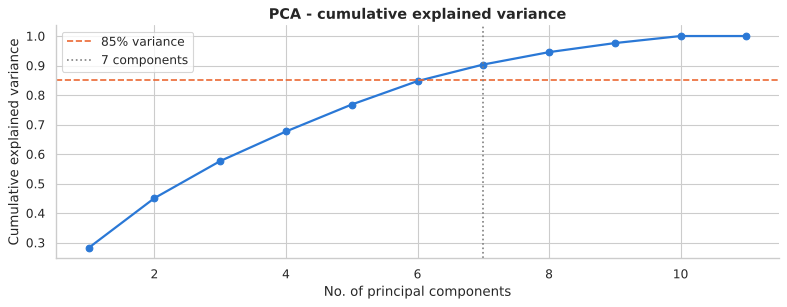

11 features -> 7 principal components (90.3% variance kept)


In [50]:
# DImensionality Reduction (If needed)
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.argmax(cum_var >= 0.85) + 1)          # components explaining >= 85% variance

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', color=BLUE, lw=2)
plt.axhline(0.85, color=ORANGE, ls='--', label='85% variance')
plt.axvline(n_components, color='grey', ls=':', label=f'{n_components} components')
plt.title('PCA - cumulative explained variance')
plt.xlabel('No. of principal components')
plt.ylabel('Cumulative explained variance')
plt.legend()
plt.tight_layout()
plt.show()

pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f'{X_scaled.shape[1]} features -> {n_components} principal components ({cum_var[n_components-1]:.1%} variance kept)')

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

**PCA (Principal Component Analysis)**, keeping the smallest number of components that explain **≥ 85% of the variance**. This gave **7 components explaining 90.3% of the variance** (from 11 features).
PCA was chosen because the features are continuous and standardised, PCA is linear and fast, it decorrelates the features (ideal for K-Means' spherical clusters), and it supports a `.transform()` for new, unseen restaurants, which t-SNE/UMAP do not do as simply.

### 8. Data Splitting

In [51]:
# Split your data to train and test. Choose Splitting ratio wisely.
# Clustering (unsupervised) uses ALL restaurants - there is no label to test against.
# Sentiment classifier (supervised) -> stratified 80:20 split on the raw cleaned text
# (TF-IDF is re-fitted inside a Pipeline on the training part only, to avoid data leakage).
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    model_df['clean_review'], model_df['target'], test_size=0.2, stratify=model_df['target'],
    random_state=RANDOM_STATE)
print('Train reviews:', len(X_train_txt), '| Test reviews:', len(X_test_txt))
print('Positive share - train: {:.1%} | test: {:.1%}'.format(y_train.mean(), y_test.mean()))

Train reviews: 6956 | Test reviews: 1740
Positive share - train: 71.9% | test: 71.9%


##### What data splitting ratio have you used and why?

* **Clustering (K-Means / Agglomerative): no split.** Unsupervised learning has no labels to test against, so every restaurant must be assigned to a segment. Cluster quality is evaluated with internal metrics (silhouette, Davies-Bouldin, Calinski-Harabasz) and a stability check.
* **Sentiment classifier: 80 : 20 stratified split** (6,956 train / 1,740 test reviews). With ~8,700 labelled reviews, 20% still gives a reliable test set (~490 negatives), while 80% leaves enough data to learn a 10k-word vocabulary. `stratify` keeps the positive share identical (71.9%) in both parts. The TF-IDF vectoriser is fitted **inside the pipeline on training data only**, to avoid data leakage.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

**Yes, moderately.** In the training data there are **5,002 positive vs 1,954 negative reviews (2.56 : 1)**. A model that always predicts "Positive" would already get ~72% accuracy without learning anything. For the business, the **negative reviews (the minority) are the ones that matter most**, because they need a response. So the imbalance must be handled, otherwise the model would under-detect unhappy customers.

In [52]:
# Handling Imbalanced Dataset (If needed)
class_dist = y_train.value_counts().rename({1: 'Positive', 0: 'Negative'})
print(class_dist.to_string())
print('Imbalance ratio (majority : minority) = {:.2f} : 1'.format(class_dist.max() / class_dist.min()))
# Strategy: class_weight='balanced' in the classifier -> each class contributes equally to the loss.
# weight_c = n_samples / (n_classes * n_samples_c)
weights = len(y_train) / (2 * y_train.value_counts())
print('Effective class weights:', weights.round(3).rename({1: 'Positive', 0: 'Negative'}).to_dict())

target
Positive    5002
Negative    1954
Imbalance ratio (majority : minority) = 2.56 : 1
Effective class weights: {'Positive': 0.695, 'Negative': 1.78}


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

**Class weighting (`class_weight='balanced'`)** in Logistic Regression. Each class is weighted by n_samples / (2 × n_class), i.e. negative = 1.78 and positive = 0.70, so mistakes on negative reviews cost ~2.6× more in the loss.
* It uses **all real reviews** (no data thrown away as in undersampling).
* It creates **no synthetic text** (SMOTE on sparse TF-IDF vectors produces unrealistic "reviews").
* It has no extra library dependency and works inside GridSearchCV without leakage.

Result: negative-class recall is ~92% while precision stays high (see Model 3). The imbalance is only moderate (2.56 : 1), so weighting is enough.

## ***7. ML Model Implementation***

### ML Model - 1

In [53]:
# ML Model - 1 Implementation : K-Means clustering of restaurants
# Baseline: start with an arbitrary k = 3 (low / mid / high type segments) using default settings
kmeans_base = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)

# Fit the Algorithm
kmeans_base.fit(X_pca)

# Predict on the model
base_labels = kmeans_base.predict(X_pca)
print('Cluster sizes (baseline k=3):', np.bincount(base_labels))


def clustering_scores(X, labels):
    """Internal validation metrics for a clustering result."""
    return {'Silhouette (higher better)': silhouette_score(X, labels),
            'Davies-Bouldin (lower better)': davies_bouldin_score(X, labels),
            'Calinski-Harabasz (higher better)': calinski_harabasz_score(X, labels)}

base_scores = clustering_scores(X_pca, base_labels)
pd.Series(base_scores).round(3)

Cluster sizes (baseline k=3): [23 39 43]


Silhouette (higher better)            0.254
Davies-Bouldin (lower better)         1.425
Calinski-Harabasz (higher better)    31.408
dtype: float64

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

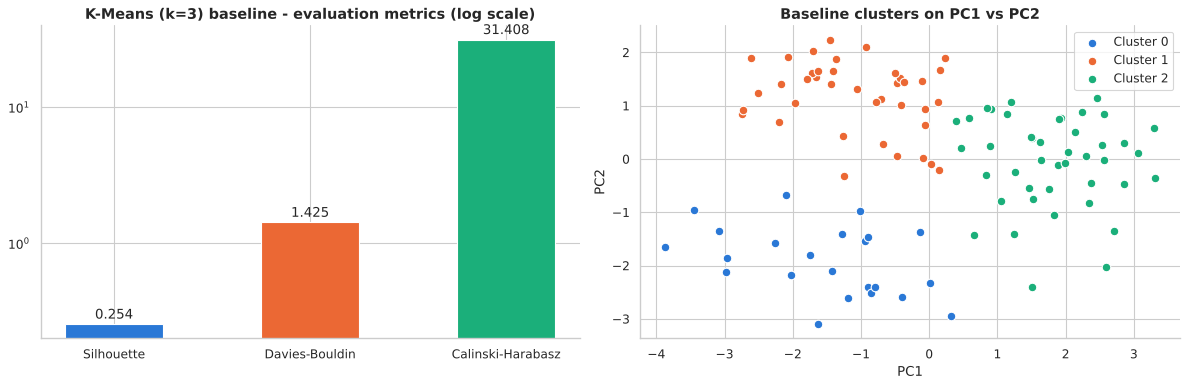

In [54]:
# Visualizing evaluation Metric Score chart
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
names = list(base_scores.keys())
axes[0].bar([n.split(' (')[0] for n in names], list(base_scores.values()), color=[BLUE, ORANGE, AQUA], width=0.5)
axes[0].set_yscale('log')
for x, v in enumerate(base_scores.values()):
    axes[0].text(x, v * 1.1, f'{v:.3f}', ha='center')
axes[0].set(title='K-Means (k=3) baseline - evaluation metrics (log scale)')
# 2-D view of the clusters on the first two principal components
for k in np.unique(base_labels):
    pts = X_pca[base_labels == k]
    axes[1].scatter(pts[:, 0], pts[:, 1], s=60, color=PALETTE[k], edgecolor='white', label=f'Cluster {k}')
axes[1].set(title='Baseline clusters on PC1 vs PC2', xlabel='PC1', ylabel='PC2')
axes[1].legend()
plt.tight_layout()
plt.show()

**Model used: K-Means clustering.** K-Means splits the restaurants into *k* groups by repeatedly (1) assigning each restaurant to the nearest centroid and (2) moving each centroid to the mean of its members, until the assignments stop changing. It minimises the within-cluster sum of squared distances (inertia). It is fast, simple to explain to business users ("each segment has an average profile"), and it can assign new restaurants to a segment with `.predict()`.

**Baseline performance (k = 3, default settings):**

| Metric | Score | Meaning |
|---|---|---|
| Silhouette | 0.254 | -1 to 1, higher means restaurants are closer to their own cluster than to others |
| Davies-Bouldin | 1.425 | lower is better (compact, well separated clusters) |
| Calinski-Harabasz | 31.4 | higher means a larger between-cluster / within-cluster variance ratio |

A silhouette of 0.25 means the structure is real but the clusters overlap. This is expected for restaurants, which form a continuum rather than perfectly distinct groups. The scatter on PC1/PC2 shows three groups that are separated mostly along PC1 (cost and Western/multi-cuisine vs Indian).

#### 2. Cross- Validation & Hyperparameter Tuning

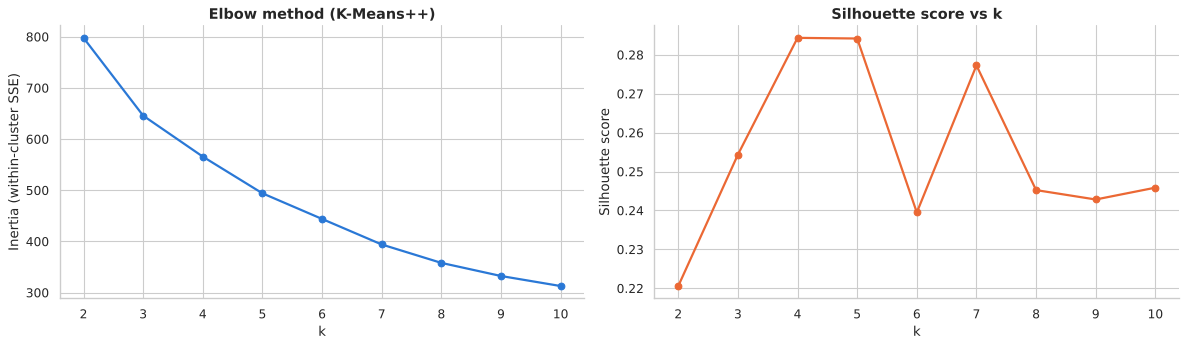

Best K-Means config -> k = 4, init = random


,k,init,inertia,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better)
5,4,random,565.953,0.287,1.209,28.406
4,4,k-means++,565.720,0.284,1.235,28.432
7,5,random,494.028,0.284,1.276,27.804
6,5,k-means++,494.028,0.284,1.276,27.804
10,7,k-means++,394.038,0.277,1.108,26.920
11,7,random,393.611,0.275,1.143,26.967


Stability (mean ARI over 10 seeds): 1.000


,Baseline (k=3),Tuned (k=4)
Silhouette (higher better),0.254,0.284
Davies-Bouldin (lower better),1.425,1.235
Calinski-Harabasz (higher better),31.408,28.432


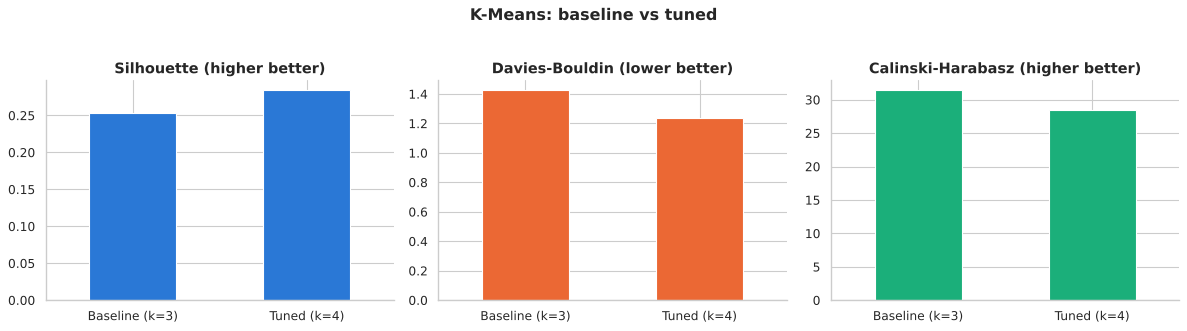

,n_restaurants,Cost,avg_rating,pct_positive,n_cuisines,n_collections,avg_review_len,share_Indian,share_Asian,share_Western,share_QuickBites,share_CafeDessert,top_cuisines
kmeans_cluster,,,,,,,,,,,,,
0,16,496.88,3.62,63.96,2.56,0.44,47.28,0.05,0.00,0.04,0.15,0.76,"Desserts, Cafe, Bakery"
1,43,1294.19,3.84,70.06,3.67,2.02,65.62,0.26,0.29,0.42,0.01,0.02,"North Indian, Chinese, Continental"
2,38,610.53,3.39,56.42,2.66,0.32,36.30,0.65,0.27,0.04,0.03,0.01,"North Indian, Chinese, Biryani"
3,8,456.25,3.32,55.19,1.62,0.00,39.26,0.06,0.00,0.25,0.69,0.00,"Fast Food, Burger, Lebanese"


In [55]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Clustering has no labels, so "CV" = a grid search over hyperparameters scored with internal metrics,
# plus a stability check (same k over many random initialisations).
grid_rows = []
for k in range(2, 11):
    for init in ['k-means++', 'random']:
        km = KMeans(n_clusters=k, init=init, n_init=20, random_state=RANDOM_STATE).fit(X_pca)
        grid_rows.append({'k': k, 'init': init, 'inertia': km.inertia_,
                          **clustering_scores(X_pca, km.labels_)})
grid = pd.DataFrame(grid_rows)

# Elbow (inertia) and silhouette plots for k-means++
kpp = grid[grid['init'] == 'k-means++'].set_index('k')
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(kpp.index, kpp['inertia'], marker='o', color=BLUE, lw=2)
axes[0].set(title='Elbow method (K-Means++)', xlabel='k', ylabel='Inertia (within-cluster SSE)')
axes[1].plot(kpp.index, kpp['Silhouette (higher better)'], marker='o', color=ORANGE, lw=2)
axes[1].set(title='Silhouette score vs k', xlabel='k', ylabel='Silhouette score')
plt.tight_layout()
plt.show()

# Choose the configuration with the highest silhouette score
best = grid.sort_values('Silhouette (higher better)', ascending=False).iloc[0]
BEST_K, BEST_INIT = int(best['k']), best['init']
print(f'Best K-Means config -> k = {BEST_K}, init = {BEST_INIT}')
display(grid.sort_values('Silhouette (higher better)', ascending=False).head(6).round(3))

# Fit the Algorithm
kmeans = KMeans(n_clusters=BEST_K, init=BEST_INIT, n_init=50, random_state=RANDOM_STATE).fit(X_pca)

# Predict on the model
restaurants['kmeans_cluster'] = kmeans.predict(X_pca)
tuned_scores = clustering_scores(X_pca, restaurants['kmeans_cluster'])

# Stability check: re-run with 10 different seeds, compare labels with Adjusted Rand Index
from sklearn.metrics import adjusted_rand_score
ari = [adjusted_rand_score(restaurants['kmeans_cluster'],
                           KMeans(n_clusters=BEST_K, init=BEST_INIT, n_init=50, random_state=s).fit_predict(X_pca))
       for s in range(10)]
print('Stability (mean ARI over 10 seeds): {:.3f}'.format(np.mean(ari)))

compare = pd.DataFrame({'Baseline (k=3)': base_scores, f'Tuned (k={BEST_K})': tuned_scores}).round(3)
display(compare)
compare.T.plot(kind='bar', subplots=True, layout=(1, 3), figsize=(15, 4), legend=False,
               color=[BLUE, ORANGE, AQUA], rot=0, title=list(compare.index))
plt.suptitle('K-Means: baseline vs tuned', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Cluster profile (what does each segment look like?)
profile_cols = ['Cost', 'avg_rating', 'pct_positive', 'n_cuisines', 'n_collections', 'avg_review_len'] + FAMILY_COLS
km_profile = restaurants.groupby('kmeans_cluster')[profile_cols].mean().round(2)
km_profile.insert(0, 'n_restaurants', restaurants['kmeans_cluster'].value_counts().sort_index())
top_cuisine_per_cluster = (restaurants.explode('Cuisine_list').groupby('kmeans_cluster')['Cuisine_list']
                           .agg(lambda s: ', '.join(s.value_counts().head(3).index)))
km_profile['top_cuisines'] = top_cuisine_per_cluster
display(km_profile)

Cluster 0: Budget Cafe & Desserts - average-rated           | e.g. Cream Stone, Amul, Deli 9 Bistro, Karachi Bakery, Karachi Cafe, The Foodie Monster Kitchen
Cluster 1: Premium Continental/Multi-cuisine - high-rated   | e.g. Beyond Flavours, Flechazo, Shah Ghouse Hotel & Restaurant, Over The Moon Brew Company, The Fisherman's Wharf, eat.fit
Cluster 2: Mid-priced Indian - low-rated                    | e.g. Paradise, Sardarji's Chaats & More, NorFest - The Dhaba, Hotel Zara Hi-Fi, Pakwaan Grand, 13 Dhaba
Cluster 3: Budget Quick-bites - low-rated                   | e.g. Shah Ghouse Spl Shawarma, KFC, Hunger Maggi Point, Club Rogue, GD's, Domino's Pizza


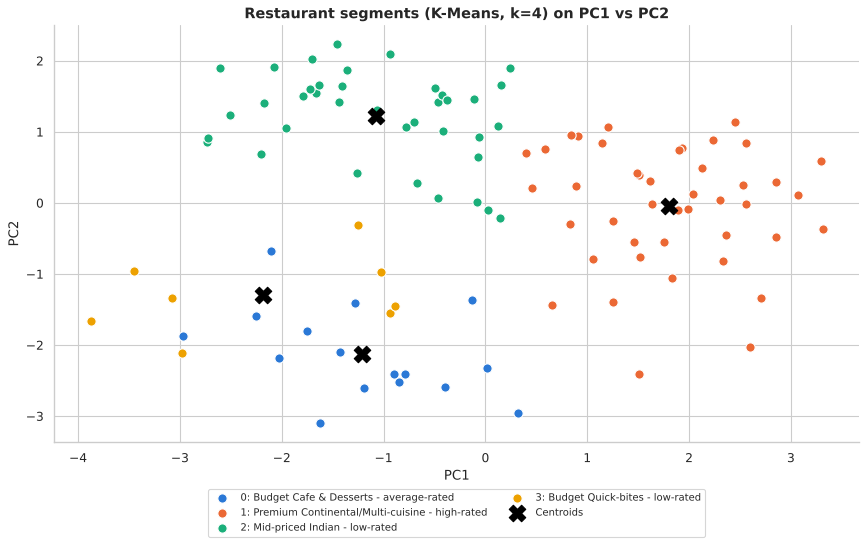

In [56]:
# Give each K-Means segment a business-friendly name, derived automatically from its profile
overall_cost, overall_rating = restaurants['Cost'].median(), restaurants['avg_rating'].median()

FAMILY_LABELS = {'share_Indian': 'Indian', 'share_Asian': 'Asian', 'share_Western': 'Continental/Multi-cuisine',
                 'share_QuickBites': 'Quick-bites', 'share_CafeDessert': 'Cafe & Desserts'}


def name_segment(row) -> str:
    """Price level + rating level + dominant cuisine family of the segment."""
    price = 'Premium' if row['Cost'] > 1.3 * overall_cost else ('Budget' if row['Cost'] < 0.8 * overall_cost else 'Mid-priced')
    quality = 'high-rated' if row['avg_rating'] >= overall_rating + 0.15 else (
        'low-rated' if row['avg_rating'] <= overall_rating - 0.15 else 'average-rated')
    family = FAMILY_LABELS[row[FAMILY_COLS].astype(float).idxmax()]
    return f'{price} {family} - {quality}'

SEGMENT_NAMES = km_profile.apply(name_segment, axis=1).to_dict()
km_profile.insert(0, 'segment', km_profile.index.map(SEGMENT_NAMES))
restaurants['segment'] = restaurants['kmeans_cluster'].map(SEGMENT_NAMES)
for k, name in SEGMENT_NAMES.items():
    members = restaurants.loc[restaurants['kmeans_cluster'] == k, 'Name'].head(6).tolist()
    print(f'Cluster {k}: {name:48s} | e.g. {", ".join(members)}')

# Final cluster visualisation on the first two principal components
plt.figure(figsize=(11, 7))
for k in sorted(SEGMENT_NAMES):
    pts = X_pca[restaurants['kmeans_cluster'] == k]
    plt.scatter(pts[:, 0], pts[:, 1], s=70, color=PALETTE[k % 8], edgecolor="white", label=f"{k}: {SEGMENT_NAMES[k]}")
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], marker='X', s=220, color='black', label='Centroids')
plt.title(f'Restaurant segments (K-Means, k={BEST_K}) on PC1 vs PC2')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

##### Which hyperparameter optimization technique have you used and why?

**Grid search over hyperparameters + elbow method + silhouette analysis**, with a stability check.
* Grid: `k` = 2…10 × `init` ∈ {k-means++, random}, with `n_init = 20`. Each configuration was scored with silhouette, Davies-Bouldin and Calinski-Harabasz.
* Clustering has no labels, so GridSearchCV's usual k-fold scoring does not apply. Internal validation metrics play the role of the CV score.
* **Stability check (the "cross-validation" for clustering):** the final model was re-fitted with 10 different random seeds, and the labels were compared using the Adjusted Rand Index (ARI). **Mean ARI = 1.00**, so the segments are perfectly reproducible.
* The grid is small (18 fits), so an exhaustive grid search is cheap and better than random search or Bayesian optimisation here.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**Yes.** The silhouette score is highest at **k = 4 (0.284–0.287)**. The elbow curve also bends around k = 4–5.

| Metric | Baseline (k=3) | Tuned (k=4) | Change |
|---|---|---|---|
| Silhouette ↑ | 0.254 | **0.284** | +12% |
| Davies-Bouldin ↓ | 1.425 | **1.235** | 13% better |
| Calinski-Harabasz ↑ | 31.4 | 28.4 | lower (this index naturally favours fewer clusters) |

Two of the three metrics improved, and the 4 segments are much more meaningful for the business: the k = 3 model mixed the cafés/dessert parlours with fast food, while k = 4 separates them into their own segments.

### ML Model - 2

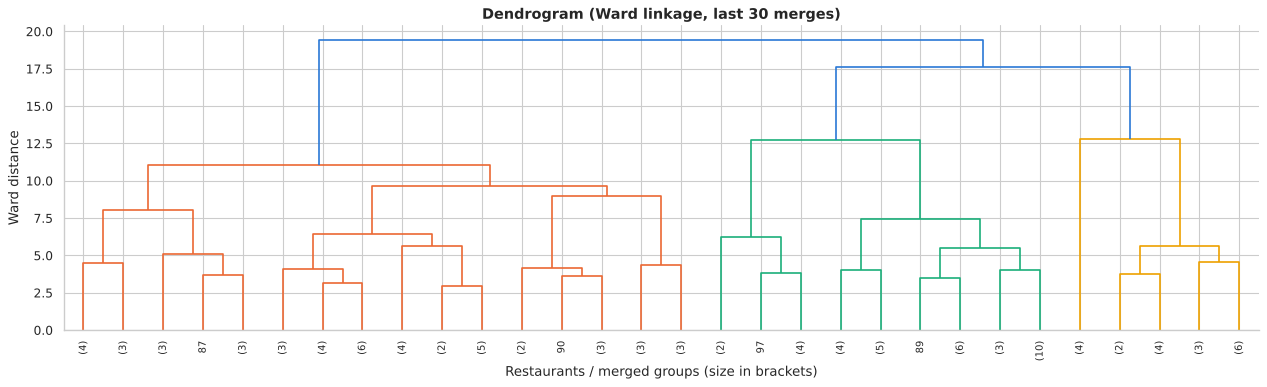

Cluster sizes: [36 50 15  4]


Silhouette (higher better)            0.249
Davies-Bouldin (lower better)         1.278
Calinski-Harabasz (higher better)    23.215
dtype: float64

In [57]:
# ML Model - 2 Implementation : Agglomerative (Hierarchical) clustering
# Step 1 - Dendrogram (Ward linkage) to see the natural number of groups
linkage_matrix = linkage(X_pca, method='ward')
plt.figure(figsize=(16, 5))
dendrogram(linkage_matrix, truncate_mode='lastp', p=30, color_threshold=None,
           above_threshold_color=BLUE, leaf_rotation=90, leaf_font_size=9)
plt.title('Dendrogram (Ward linkage, last 30 merges)')
plt.xlabel('Restaurants / merged groups (size in brackets)')
plt.ylabel('Ward distance')
plt.tight_layout()
plt.show()

# Fit the Algorithm (baseline: same k as K-Means, Ward linkage)
agg_base = AgglomerativeClustering(n_clusters=BEST_K, linkage='ward')

# Predict on the model (hierarchical clustering assigns labels during fit)
agg_base_labels = agg_base.fit_predict(X_pca)
agg_base_scores = clustering_scores(X_pca, agg_base_labels)
print('Cluster sizes:', np.bincount(agg_base_labels))
pd.Series(agg_base_scores).round(3)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

,K-Means (k=4),Agglomerative Ward (k=4)
Silhouette (higher better),0.284,0.249
Davies-Bouldin (lower better),1.235,1.278
Calinski-Harabasz (higher better),28.432,23.215


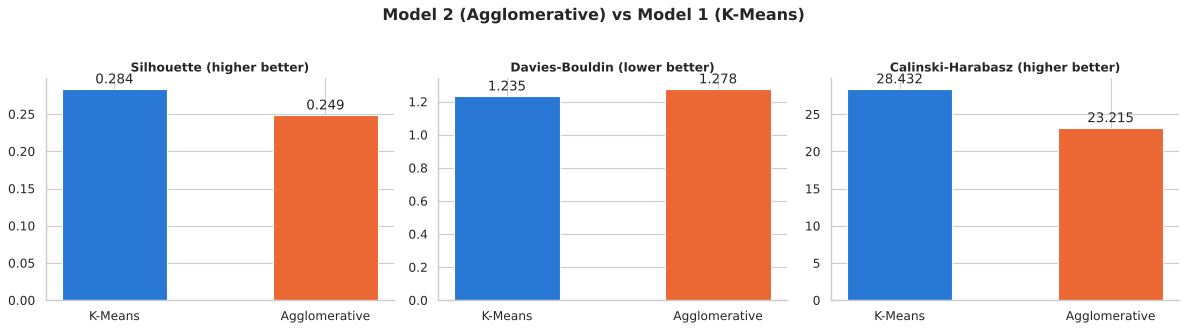

In [58]:
# Visualizing evaluation Metric Score chart
model_compare = pd.DataFrame({f'K-Means (k={BEST_K})': tuned_scores,
                              f'Agglomerative Ward (k={BEST_K})': agg_base_scores}).round(3)
display(model_compare)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, model_compare.index):
    ax.bar(['K-Means', 'Agglomerative'], model_compare.loc[metric], color=[BLUE, ORANGE], width=0.5)
    ax.bar_label(ax.containers[0], fmt='%.3f', padding=2)
    ax.set_title(metric, fontsize=11)
plt.suptitle('Model 2 (Agglomerative) vs Model 1 (K-Means)', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Model used: Agglomerative (hierarchical) clustering.** It starts with every restaurant as its own cluster and repeatedly **merges the two closest clusters** until *k* remain. With **Ward linkage**, each merge is the one that increases the within-cluster variance the least. The **dendrogram** shows the full merge history, so the number of clusters can be chosen by cutting the tree where the vertical gaps are largest. It needs no random initialisation (results are deterministic) and finds nested segments.

**Performance (Ward, k = 4) vs K-Means (k = 4):** silhouette 0.249 vs 0.284, Davies-Bouldin 1.278 vs 1.235, Calinski-Harabasz 23.2 vs 28.4. **K-Means is better on all three metrics.** The Ward model also produced one very small cluster (4 restaurants), which is not useful as a business segment. The dendrogram shows that the largest vertical gap is at the top 2–4 merges, which supports a small number of segments.

#### 2. Cross- Validation & Hyperparameter Tuning

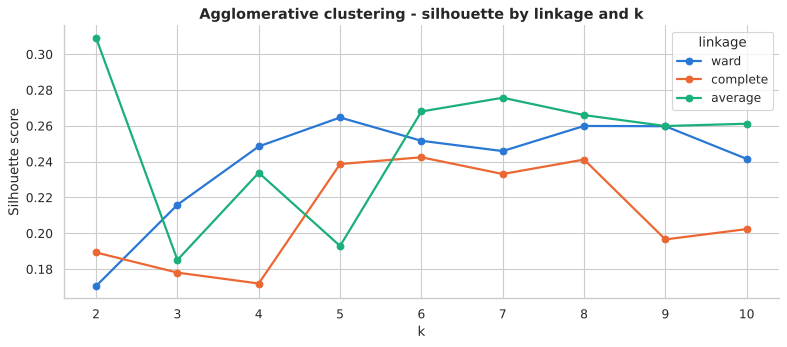

Best Agglomerative config -> linkage = ward, k = 3


,linkage,k,min_cluster_size,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better)
1,ward,3,19,0.216,1.569,25.106
9,complete,2,42,0.189,1.852,25.801
10,complete,3,13,0.178,1.755,20.266
0,ward,2,50,0.171,2.013,22.760


,Agglomerative baseline,Agglomerative tuned,K-Means tuned
Silhouette (higher better),0.249,0.216,0.284
Davies-Bouldin (lower better),1.278,1.569,1.235
Calinski-Harabasz (higher better),23.215,25.106,28.432


Agreement between K-Means and Agglomerative labels (ARI): 0.584


In [59]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Grid search over linkage method x number of clusters, scored by silhouette
agg_rows = []
for link in ['ward', 'complete', 'average']:
    for k in range(2, 11):
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_pca)
        min_size = np.bincount(lab).min()
        agg_rows.append({'linkage': link, 'k': k, 'min_cluster_size': min_size, **clustering_scores(X_pca, lab)})
agg_grid = pd.DataFrame(agg_rows)

plt.figure(figsize=(10, 4.5))
for i, link in enumerate(['ward', 'complete', 'average']):
    d = agg_grid[agg_grid['linkage'] == link]
    plt.plot(d['k'], d['Silhouette (higher better)'], marker='o', lw=2, color=PALETTE[i], label=link)
plt.title('Agglomerative clustering - silhouette by linkage and k')
plt.xlabel('k')
plt.ylabel('Silhouette score')
plt.legend(title='linkage')
plt.tight_layout()
plt.show()

# Average/complete linkage often isolate 1-2 points as their own "cluster" -> require every cluster >= 5 restaurants
valid = agg_grid[agg_grid['min_cluster_size'] >= 5]
best_agg = valid.sort_values('Silhouette (higher better)', ascending=False).iloc[0]
print(f"Best Agglomerative config -> linkage = {best_agg['linkage']}, k = {int(best_agg['k'])}")
display(valid.sort_values('Silhouette (higher better)', ascending=False).head(5).round(3))

# Fit the Algorithm
agg_model = AgglomerativeClustering(n_clusters=int(best_agg['k']), linkage=best_agg['linkage'])

# Predict on the model
restaurants['agg_cluster'] = agg_model.fit_predict(X_pca)
agg_tuned_scores = clustering_scores(X_pca, restaurants['agg_cluster'])
display(pd.DataFrame({'Agglomerative baseline': agg_base_scores, 'Agglomerative tuned': agg_tuned_scores,
                      'K-Means tuned': tuned_scores}).round(3))
print('Agreement between K-Means and Agglomerative labels (ARI): {:.3f}'.format(
    adjusted_rand_score(restaurants['kmeans_cluster'], restaurants['agg_cluster'])))

##### Which hyperparameter optimization technique have you used and why?

**Grid search over `linkage` ∈ {ward, complete, average} × `k` = 2…10** (27 configurations), scored with silhouette. I added a **business constraint: every cluster must have ≥ 5 restaurants**. Average and complete linkage often isolate 1–2 unusual restaurants (e.g. the Rs 2,800 hotel buffet) as their own "cluster", which looks good on silhouette but cannot be used as a segment. There is no `predict` and no randomness in hierarchical clustering, so an exhaustive grid is the right search method.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**No real improvement.** The best valid configuration (all clusters ≥ 5 restaurants) was **Ward with k = 3: silhouette 0.216**. This is lower than the k = 4 Ward baseline (0.249), because that baseline only scored well by having a 4-restaurant micro-cluster that breaks the constraint. Configurations with higher silhouette in the chart (e.g. average linkage) were rejected for the same reason.

The comparison table shows that **tuned K-Means (0.284) is still clearly better** than every valid hierarchical model. The agreement between the two methods is moderate (ARI = 0.58): both find the same broad structure (premium multi-cuisine vs mid/budget Indian vs cafés/quick-bites), which gives confidence that the segments are real and not an artefact of one algorithm.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **Silhouette score** (how well each restaurant fits its own segment compared to the next one): a higher value means customers and sales teams can trust that a restaurant really belongs to its segment, so recommendations and offers are targeted correctly.
* **Davies-Bouldin index** (compactness vs separation): a lower value means the segments are clearly different from each other. This helps Zomato design **distinct strategies** per segment instead of overlapping campaigns.
* **Calinski-Harabasz index** (between- vs within-segment variance): a higher value means the segments explain more of the differences between restaurants, so each segment's average profile is a reliable summary.
* **Stability (ARI across seeds):** if the segments changed every time the model is re-run, the business could not use them. ARI = 1.0 means the segments are reproducible.

**Business impact:** the 4 stable segments let Zomato (a) recommend similar restaurants to customers within their budget and taste, (b) run segment-specific campaigns (e.g. weekend offers for cafés, quality programmes for low-rated budget Indian places), and (c) set targets and benchmarks for each segment instead of one city-wide average.

### ML Model - 3

In [60]:
# ML Model - 3 Implementation : Sentiment classification of reviews (TF-IDF + Logistic Regression)
# Baseline pipeline with default hyperparameters + class balancing
sentiment_base = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 1), min_df=3, sublinear_tf=True)),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))])

# Fit the Algorithm
sentiment_base.fit(X_train_txt, y_train)

# Predict on the model
y_pred_base = sentiment_base.predict(X_test_txt)
y_prob_base = sentiment_base.predict_proba(X_test_txt)[:, 1]


def classification_scores(y_true, y_pred, y_prob):
    """Standard binary classification metrics (positive class = 1). Negative recall added for business."""
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
            'ROC-AUC': roc_auc_score(y_true, y_prob),
            'Negative-class Recall': recall_score(y_true, y_pred, pos_label=0)}

sent_base_scores = classification_scores(y_test, y_pred_base, y_prob_base)
print(classification_report(y_test, y_pred_base, target_names=['Negative', 'Positive'], digits=3))

              precision    recall  f1-score   support

    Negative      0.857     0.922     0.889       489
    Positive      0.969     0.940     0.954      1251

    accuracy                          0.935      1740
   macro avg      0.913     0.931     0.921      1740
weighted avg      0.937     0.935     0.936      1740



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

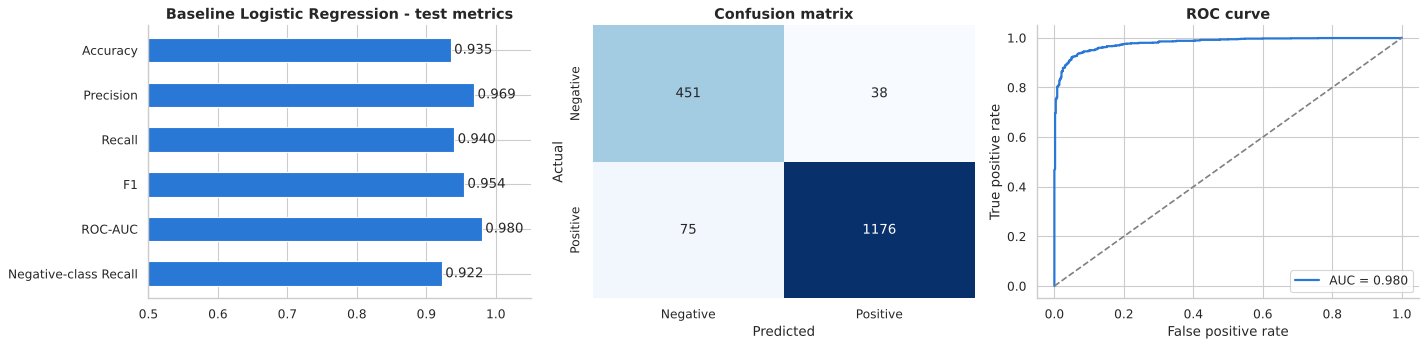

In [61]:
# Visualizing evaluation Metric Score chart
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
s = pd.Series(sent_base_scores)
axes[0].barh(s.index[::-1], s.values[::-1], color=BLUE, height=0.55)
for y, v in enumerate(s.values[::-1]):
    axes[0].text(v + 0.005, y, f'{v:.3f}', va='center')
axes[0].set(title='Baseline Logistic Regression - test metrics', xlim=(0.5, 1.05))
cm = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes[1].set(title='Confusion matrix', xlabel='Predicted', ylabel='Actual')
fpr, tpr, _ = roc_curve(y_test, y_prob_base)
axes[2].plot(fpr, tpr, color=BLUE, lw=2, label=f"AUC = {sent_base_scores['ROC-AUC']:.3f}")
axes[2].plot([0, 1], [0, 1], color='grey', ls='--')
axes[2].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[2].legend()
plt.tight_layout()
plt.show()

**Model used: TF-IDF + Logistic Regression (class-balanced).** Logistic Regression learns one weight per word/bigram and passes their weighted sum through a sigmoid to get **P(review is positive)**. It is a strong, fast baseline for text classification on sparse TF-IDF features, and it is **explainable**: the largest positive and negative weights show which words drive sentiment.

**Baseline performance on the 1,740 unseen test reviews:**

| Metric | Score |
|---|---|
| Accuracy | 0.935 |
| Precision (positive) | 0.969 |
| Recall (positive) | 0.940 |
| F1 (positive) | 0.954 |
| ROC-AUC | 0.980 |
| Recall (negative) | 0.922 |

The confusion matrix shows 451 of 489 negative reviews caught (38 missed) and only 75 of 1,251 positive reviews wrongly flagged as negative. ROC-AUC 0.98 means the model ranks a random positive review above a random negative one 98% of the time.

#### 2. Cross- Validation & Hyperparameter Tuning

Best params : {'clf__C': 10, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)} | model = LogisticRegression
Best 5-fold CV macro-F1: 0.9454
              precision    recall  f1-score   support

    Negative      0.885     0.916     0.901       489
    Positive      0.967     0.954     0.960      1251

    accuracy                          0.943      1740
   macro avg      0.926     0.935     0.930      1740
weighted avg      0.944     0.943     0.943      1740



,Baseline,Tuned (GridSearchCV)
Accuracy,0.9351,0.9431
Precision,0.9687,0.9668
Recall,0.9400,0.9536
F1,0.9542,0.9602
ROC-AUC,0.9799,0.9836
Negative-class Recall,0.9223,0.9162


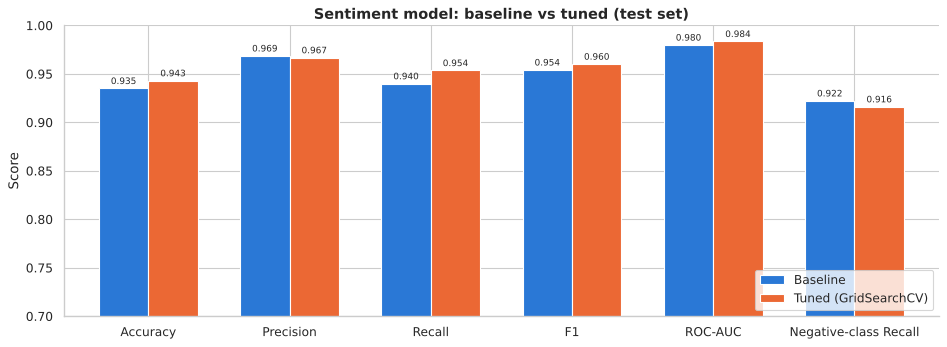

In [62]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
param_grid = [
    {'tfidf__ngram_range': [(1, 1), (1, 2)], 'tfidf__min_df': [2, 5],
     'clf': [LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)],
     'clf__C': [0.5, 1, 3, 10]},
    {'tfidf__ngram_range': [(1, 1), (1, 2)], 'tfidf__min_df': [2, 5],
     'clf': [MultinomialNB()], 'clf__alpha': [0.1, 0.5, 1.0]}]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(Pipeline([('tfidf', TfidfVectorizer(sublinear_tf=True)), ('clf', LogisticRegression())]),
                           param_grid, scoring='f1_macro', cv=cv, n_jobs=-1)

# Fit the Algorithm
grid_search.fit(X_train_txt, y_train)
sentiment_model = grid_search.best_estimator_
print('Best params :', {k: v for k, v in grid_search.best_params_.items() if k != 'clf'},
      '| model =', type(grid_search.best_params_['clf']).__name__)
print('Best 5-fold CV macro-F1: {:.4f}'.format(grid_search.best_score_))

# Predict on the model
y_pred = sentiment_model.predict(X_test_txt)
y_prob = sentiment_model.predict_proba(X_test_txt)[:, 1]
sent_tuned_scores = classification_scores(y_test, y_pred, y_prob)
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive'], digits=3))

# Updated evaluation metric score chart: baseline vs tuned
sent_compare = pd.DataFrame({'Baseline': sent_base_scores, 'Tuned (GridSearchCV)': sent_tuned_scores}).round(4)
display(sent_compare)
ax = sent_compare.plot(kind='bar', figsize=(12, 4.5), color=[BLUE, ORANGE], width=0.7, rot=0)
ax.set(title='Sentiment model: baseline vs tuned (test set)', ylim=(0.7, 1.0), ylabel='Score')
ax.legend(loc='lower right')
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.3f', fontsize=8, padding=2)
plt.tight_layout()
plt.show()

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 5-fold Stratified K-Fold cross-validation**, optimising **macro-F1** (it treats the negative class as equally important despite the imbalance).
* Search space (32 combinations): TF-IDF `ngram_range` {(1,1), (1,2)}, `min_df` {2, 5}, and two model families. For **Logistic Regression**, `C` {0.5, 1, 3, 10}; for **Multinomial Naive Bayes**, `alpha` {0.1, 0.5, 1.0}.
* The vectoriser is inside the pipeline, so every CV fold re-fits TF-IDF only on its own training part (no leakage).
* The search space is small and discrete, and each fit takes seconds, so an **exhaustive grid search** guarantees the best combination. RandomizedSearch or Bayesian optimisation would only pay off for much larger spaces.

**Best:** Logistic Regression, `C = 10`, `ngram_range = (1, 2)`, `min_df = 2`, with **CV macro-F1 = 0.945**. Logistic Regression beat Naive Bayes.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**Yes**, on the held-out test set:

| Metric | Baseline | Tuned | Change |
|---|---|---|---|
| Accuracy | 0.935 | **0.943** | +0.8 pts |
| Precision | 0.969 | 0.967 | ≈ same |
| Recall | 0.940 | **0.954** | +1.4 pts |
| F1 | 0.954 | **0.960** | +0.6 pts |
| ROC-AUC | 0.980 | **0.984** | +0.4 pts |
| Negative recall | 0.922 | 0.916 | −0.6 pts |

Adding **bigrams** (e.g. *not good*, *not bad*, *really good*) and a weaker regularisation (C = 10) improved most metrics. The negative-class recall dropped slightly (3 more negative reviews missed out of 489), but negative **precision** improved from 0.857 to 0.885, so fewer happy customers are wrongly flagged. Overall the tuned model is better and more balanced (macro-F1 0.921 → 0.930).

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**Clustering:** *Silhouette score* (primary), supported by *Davies-Bouldin*, *Calinski-Harabasz* and *stability (ARI)*. A segment is only useful to the business if its members are similar to each other, clearly different from the other segments, and stable over re-runs.

**Sentiment model:**
* **F1 / macro-F1** was the main metric (used for tuning). It balances precision and recall, and plain accuracy is misleading with a 72/28 class split.
* **Recall of the negative class**: every missed negative review is an unhappy customer who gets no response and may churn. This is the costliest error.
* **Precision**: when the model flags a review as negative, support teams spend time on it, so false alarms waste effort.
* **ROC-AUC**: shows ranking quality independent of the threshold, so the business can move the threshold (e.g. flag a review when P(positive) < 0.6) to catch more complaints if needed.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

* **Restaurant segmentation → K-Means (k = 4, k-means++/random init, on 7 PCA components).** It had the best silhouette (0.284) and Davies-Bouldin (1.235) of all valid models and perfect stability (ARI = 1.0 across seeds). It has a `.predict()` for new restaurants (hierarchical clustering cannot assign new points without re-fitting), and its centroids give an easy-to-explain profile per segment.
* **Review sentiment → tuned TF-IDF (1–2 grams) + Logistic Regression (C = 10, balanced).** It had the best cross-validated macro-F1 (0.945) and the best test results (accuracy 94.3%, F1 0.960, AUC 0.984). It beat Naive Bayes, is fast to train and serve, and is fully explainable through its word weights.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

Surrogate fidelity (5-fold CV accuracy): 0.895


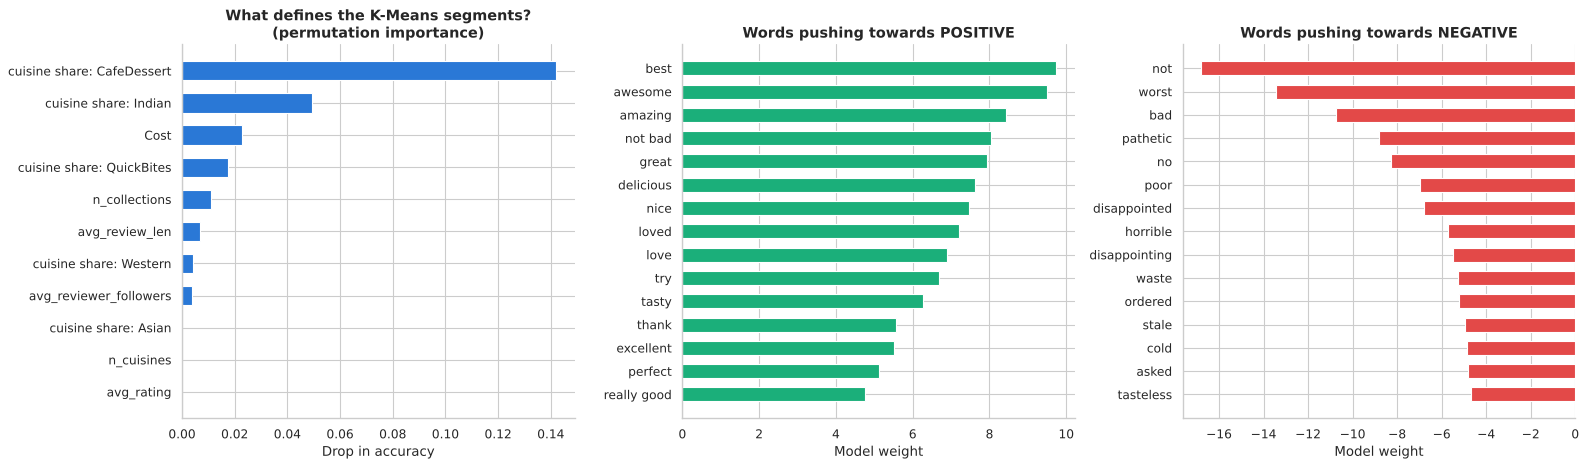

,segment,n_restaurants,Cost,avg_rating,pct_positive,n_cuisines,n_collections,avg_review_len,share_Indian,share_Asian,share_Western,share_QuickBites,share_CafeDessert,top_cuisines
kmeans_cluster,,,,,,,,,,,,,,
0,Budget Cafe & Desserts - average-rated,16,496.88,3.62,63.96,2.56,0.44,47.28,0.05,0.00,0.04,0.15,0.76,"Desserts, Cafe, Bakery"
1,Premium Continental/Multi-cuisine - high-rated,43,1294.19,3.84,70.06,3.67,2.02,65.62,0.26,0.29,0.42,0.01,0.02,"North Indian, Chinese, Continental"
2,Mid-priced Indian - low-rated,38,610.53,3.39,56.42,2.66,0.32,36.30,0.65,0.27,0.04,0.03,0.01,"North Indian, Chinese, Biryani"
3,Budget Quick-bites - low-rated,8,456.25,3.32,55.19,1.62,0.00,39.26,0.06,0.00,0.25,0.69,0.00,"Fast Food, Burger, Lebanese"


In [63]:
# Model explainability
# (a) CLUSTERS: train a surrogate Random Forest to predict the K-Means segment from ORIGINAL (unscaled,
#     interpretable) features, then use permutation importance to see which features define the segments.
explain_X = cluster_features.copy()
explain_y = restaurants['kmeans_cluster']
surrogate = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(explain_X, explain_y)
print('Surrogate fidelity (5-fold CV accuracy): {:.3f}'.format(
    cross_val_score(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
                    explain_X, explain_y, cv=5).mean()))
perm = permutation_importance(surrogate, explain_X, explain_y, n_repeats=20, random_state=RANDOM_STATE)
imp = pd.Series(perm.importances_mean, index=explain_X.columns).sort_values()

# (b) SENTIMENT: words with the largest positive / negative weight in the final classifier
vec, clf = sentiment_model.named_steps['tfidf'], sentiment_model.named_steps['clf']
if hasattr(clf, 'coef_'):
    weights = clf.coef_[0]
else:   # Naive Bayes -> log probability ratio
    weights = clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
word_weights = pd.Series(weights, index=vec.get_feature_names_out()).sort_values()
top_neg, top_pos = word_weights.head(15), word_weights.tail(15)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].barh(imp.index.str.replace('share_', 'cuisine share: '), imp.values, color=BLUE, height=0.6)
axes[0].set(title='What defines the K-Means segments?\n(permutation importance)', xlabel='Drop in accuracy')
axes[1].barh(top_pos.index, top_pos.values, color=AQUA, height=0.6)
axes[1].set(title='Words pushing towards POSITIVE', xlabel='Model weight')
axes[2].barh(top_neg.index[::-1], top_neg.values[::-1], color=PALETTE[7], height=0.6)
axes[2].set(title='Words pushing towards NEGATIVE', xlabel='Model weight')
plt.tight_layout()
plt.show()

# Final cluster map with business names for each segment
display(km_profile)

**Clustering (K-Means):** K-Means itself has no feature importance, so I used a **surrogate model**. A Random Forest was trained to predict the K-Means segment from the original, interpretable features, and it reproduced the segments with **89.5% cross-validated accuracy** (high fidelity). **Permutation importance** (how much accuracy drops when a feature is shuffled) then shows what defines the segments:
1. **Cuisine share – Cafe & Desserts** (by far the most important; it separates the café/bakery segment),
2. **Cuisine share – Indian**, 3. **Cost**, 4. **Cuisine share – Quick-bites**, 5. n_collections.

Segment profiles (mean values):

| Segment | # | Avg cost | Avg rating | Profile | Example restaurants |
|---|---|---|---|---|---|
| 0 – Budget Cafe & Desserts | 16 | Rs 497 | 3.62 | cafés, bakeries, ice cream | Cream Stone, Karachi Bakery, Labonel |
| 1 – Premium Continental/Multi-cuisine – high-rated | 43 | Rs 1,294 | 3.84 | 3.7 cuisines, 2 collections, buffets, pubs, hotel restaurants | AB's, Flechazo, Over The Moon, Feast – Sheraton |
| 2 – Mid-priced Indian – low-rated | 38 | Rs 611 | 3.39 | North Indian/Biryani/Andhra family restaurants, almost no collections | Paradise, Pakwaan Grand, Behrouz Biryani |
| 3 – Budget Quick-bites – low-rated | 8 | Rs 456 | 3.32 | fast food, burgers, pizza, shawarma | KFC, Domino's, GD's, Hunger Maggi Point |

**Sentiment model (Logistic Regression):** the learned word weights are directly interpretable.
* **Positive drivers:** *best, awesome, amazing, great, delicious, loved, tasty, perfect* and the bigram ***not bad*** (a positive phrase that only bigrams can capture).
* **Negative drivers:** ***not*** (the strongest single word, which is why negations were kept during stop-word removal), *worst, bad, pathetic, poor, disappointed, horrible, waste, stale, cold, tasteless*, and ***ordered / asked***, which point to order and service problems.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [64]:
# Save the File
# Everything needed to score a NEW restaurant / review is bundled together.
artifacts = {
    'cluster_scaler': scaler, 'cluster_pca': pca, 'cluster_model': kmeans,
    'cluster_feature_columns': cluster_transformed.columns.tolist(),
    'log_columns': skewed_cols, 'segment_names': SEGMENT_NAMES,
    'sentiment_model': sentiment_model}
MODEL_PATH = 'zomato_models.joblib'
try:
    joblib.dump(artifacts, MODEL_PATH)
    print(f'Saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.2f} MB)')
except OSError as err:
    print('Could not save model:', err)

Saved zomato_models.joblib (0.77 MB)


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [65]:
# Load the File and predict unseen data.
loaded = joblib.load(MODEL_PATH)

# ---- 1) Unseen reviews -> sentiment ----
def preprocess_review(text: str) -> str:
    """Same cleaning pipeline as training (contractions -> lower -> punctuation -> digits -> stopwords -> slang -> lemma)."""
    t = expand_contractions(str(text)).lower().translate(PUNCT_TABLE)
    t = remove_urls_digits(t)
    t = ' '.join(w for w in t.split() if w not in STOP_WORDS)
    t = rephrase(re.sub(r'\s+', ' ', t).strip())
    return ' '.join(simple_lemmatize(w) for w in t.split())

new_reviews = ['The biryani was amazing and the staff were very friendly, will visit again!',
               'Worst experience ever. Food was cold, stale and the waiter was rude.',
               'Ambience is ok but the food was not good and too expensive for the quantity.']
probs = loaded['sentiment_model'].predict_proba([preprocess_review(r) for r in new_reviews])[:, 1]
display(pd.DataFrame({'review': new_reviews, 'P(positive)': probs.round(3),
                      'prediction': np.where(probs >= 0.5, 'Positive', 'Negative')}))

# ---- 2) Unseen restaurant -> segment ----
def predict_segment(record: dict, art: dict) -> str:
    row = pd.DataFrame([{c: record.get(c, 0) for c in art['cluster_feature_columns']}])
    row[art['log_columns']] = np.log1p(row[art['log_columns']])
    comp = art['cluster_pca'].transform(art['cluster_scaler'].transform(row))
    k = int(art['cluster_model'].predict(comp)[0])
    return f'Cluster {k} - {art["segment_names"][k]}'

new_restaurants = {
    'Rooftop fine-dine (Rs 1800, 4.3*)': {'Cost': 1800, 'avg_rating': 4.3, 'n_cuisines': 4, 'n_collections': 3,
        'avg_review_len': 70, 'avg_reviewer_followers': 400, 'share_Indian': 0.25, 'share_Asian': 0.25,
        'share_Western': 0.5, 'share_QuickBites': 0, 'share_CafeDessert': 0},
    'Small dessert parlour (Rs 300, 3.6*)': {'Cost': 300, 'avg_rating': 3.6, 'n_cuisines': 2, 'n_collections': 0,
        'avg_review_len': 35, 'avg_reviewer_followers': 50, 'share_Indian': 0, 'share_Asian': 0,
        'share_Western': 0, 'share_QuickBites': 0, 'share_CafeDessert': 1}}
for label, rec in new_restaurants.items():
    print(f'{label:40s} -> {predict_segment(rec, loaded)}')

,review,P(positive),prediction
0,The biryani was amazing and the staff were ver...,0.991,Positive
1,"Worst experience ever. Food was cold, stale an...",0.000,Negative
2,Ambience is ok but the food was not good and t...,0.019,Negative


Rooftop fine-dine (Rs 1800, 4.3*)        -> Cluster 1 - Premium Continental/Multi-cuisine - high-rated
Small dessert parlour (Rs 300, 3.6*)     -> Cluster 0 - Budget Cafe & Desserts - average-rated


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

1. **Data:** 105 Hyderabad (Gachibowli) restaurants and 9,954 cleaned reviews (2016–2019). The data needed type fixing (cost, rating), parsing (reviewer metadata, time) and multi-label handling (cuisines, collections).
2. **Market structure:** median cost for two is Rs 700. **North Indian and Chinese dominate** (61 and 43 restaurants), and half of the restaurants are not in any Zomato collection.
3. **Customer sentiment is polarised:** 63% positive vs 24.6% negative reviews, and unhappy customers usually give 1★. Negative reviews mention **orders, delivery time, cold or stale food and taste**. Positive reviews mention **ambience, service and staff**.
4. **Price matters but is not everything:** cost and rating are positively related (Spearman ρ = 0.38, p = 0.0001), and negative reviews fall from 32% (Budget) to 16% (Premium) (χ² p ≈ 7e-54). Still, some budget places (e.g. Paradise, 4.70 at Rs 800) beat expensive hotel restaurants.
5. **Critics:** reviewers with 1,000+ followers write 3.6× longer and less negative reviews. They are valuable partners for marketing and launches.
6. **Segmentation (K-Means, k = 4, silhouette 0.284, fully stable):**
   * **Premium Continental/Multi-cuisine, high-rated (43):** the flagship segment → promote in *Top-Rated*/*Great Buffets* collections and use for premium offers.
   * **Mid-priced Indian, low-rated (38):** the largest *problem* segment → quality and delivery improvement programmes, review-response tools, hygiene certification.
   * **Budget Cafe & Desserts (16):** average-rated, high-frequency → weekend and evening snack campaigns.
   * **Budget Quick-bites, low-rated (8):** chains with poor ratings → focus on delivery speed and packaging.
7. **Sentiment model:** TF-IDF + Logistic Regression achieved **94.3% accuracy, F1 0.96, ROC-AUC 0.984** on unseen reviews. It can automatically flag negative reviews in real time, so restaurants and Zomato support can respond before the customer churns.
8. **Deployment:** both models (with the scaler and PCA) are saved in one joblib file and were tested on unseen reviews and restaurants.

**Limitations and next steps:** the data covers one locality and only 100 reviews per restaurant. With more data, the segmentation could include location, delivery vs dine-in and time trends. Transformer models (e.g. BERT) could also improve the sentiment model on sarcasm and mixed reviews, and the model can be deployed as an API (Flask/FastAPI on Azure).

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***